# Decision Tree From Scratch — Tests & Experiments

This notebook has **two sections** that build on each other:

| Section | What you do | Library methods involved |
|---|---|---|
| **I — Unit tests** | Check that your `Node` and `DecisionTree` classes in `DT_Library.py` are correct | every method of both classes |
| **II — Experimental investigation** | Use the *verified* tree to study over/underfitting, pruning, criteria, cross-validation and tuning on a real dataset | `fit`, `predict`, `depth_`, `n_nodes_`, `feature_importances_`, `root_`, hyperparameters |

> **Rule:** do not start Section II until **every** cell of Section I runs without an `AssertionError`.
> A wrong `_find_best_split` or `predict` would silently ruin every experiment afterwards.

**Files needed in the same folder:** `DT_Library.py` and `EuroRail_Survey.csv`.

# Section I — Unit Tests for `DT_Library.py`

Each unit test below targets one part of the library. Read the short description, run the cell, and fix your code if an assertion fails.
Several tests use **mocks** (`unittest.mock.MagicMock`): a helper method is replaced by a fake one so that we can check *how* another method uses it — for example that `_build_tree` passes the right data and depth to the recursive calls.

## Unit Test 1 — The `Node` Class

In this part, you will implement the `Node` class used to represent a single node in the Decision Tree.

A Decision Tree consists of multiple nodes. Each node may either:

* represent a **decision/split** in the tree, or
* represent a **leaf** containing the final prediction.

Your task is to complete the `Node` class constructor so that it correctly stores all the information associated with a node.

### What you need to implement

The `Node` class contains the following attributes:

* `feature_index`: The index of the feature used to split the node.
* `threshold`: The threshold value used for the split.
* `left`: The left child node.
* `right`: The right child node.
* `value`: The predicted class when the node is a leaf.
* `samples`: The number of training samples that reach this node.
* `impurity`: The impurity value of the node, such as Entropy or Gini impurity.

You should make sure that the constructor correctly assigns the provided values to the corresponding attributes.

### Important Notes

* Not every attribute is required for every type of node.
* For example, a leaf node does not need a `feature_index` or `threshold`.
* A non-leaf node may have `left` and `right` child nodes.
* Use `None` when an attribute is not applicable.
* Do not modify the class interface or rename the attributes.

After implementing the class, run the provided test cases.

The tests will check different situations, including:

1. Creating an internal node.
2. Creating a leaf node.
3. Connecting parent and child nodes.
4. Preserving the relationship between node objects.
5. Handling valid edge-case values.
6. Building a small multi-level tree using multiple `Node` objects.

Your implementation is considered correct when all provided tests pass successfully.

In [1]:
import numpy as np
from unittest.mock import MagicMock
from DT_Library import Node, DecisionTree

# Test 1 — Empty node (all attributes default to None)
root = Node()
assert root.left is None
assert root.right is None
assert root.value is None

# Test 2 — Leaf node (with left and right childs equals None)
leaf = Node(
    value=1,
    samples=6,
    impurity=0.0
)

assert leaf.feature_index is None
assert leaf.threshold is None
assert leaf.left is None
assert leaf.right is None
assert leaf.value == 1
assert leaf.samples == 6
assert leaf.impurity == 0.0
assert leaf.is_leaf() is True

# Test 3 — Parent/child relationship
left_child = Node(
    feature_index=0,
    threshold=2.5,
    samples=4,
    impurity=0.25
)

right_child = Node(
    value=1,
    samples=6,
    impurity=0.0
)

parent = Node(
    feature_index=1,
    threshold=10.0,
    left=left_child,
    right=right_child,
    samples=10,
    impurity=0.48
)

assert parent.left is left_child
assert parent.right is right_child

assert parent.left.feature_index == 0
assert parent.left.threshold == 2.5
assert parent.left.samples == 4

assert parent.right.value == 1
assert parent.right.samples == 6


# Test 4 — Object identity must be preserved
# The constructor should store the exact child objects,
# not copies of them.
child = Node(value=0, samples=3, impurity=0.0)
parent = Node(left=child)

assert parent.left is child

child.value = 1

assert parent.left.value == 1
assert parent.is_leaf() is False

# Test 5 — Different valid Python values should be preserved
node = Node(
    feature_index=0,
    threshold=0.0,
    samples=0,
    impurity=0.0,
    value=None
)

assert node.feature_index == 0
assert node.threshold == 0.0
assert node.samples == 0
assert node.impurity == 0.0
assert node.value is None


# Test 6 — Complete three-level tree
leaf_1 = Node(value=0, samples=2, impurity=0.0)
leaf_2 = Node(value=1, samples=3, impurity=0.0)

middle = Node(
    feature_index=2,
    threshold=7.5,
    left=leaf_1,
    right=leaf_2,
    samples=5,
    impurity=0.48
)

leaf_3 = Node(value=1, samples=5, impurity=0.0)

root = Node(
    feature_index=0,
    threshold=4.5,
    left=middle,
    right=leaf_3,
    samples=10,
    impurity=0.5
)

assert root.left is middle
assert root.right is leaf_3

assert root.left.left is leaf_1
assert root.left.right is leaf_2

assert root.left.left.value == 0
assert root.left.right.value == 1
assert root.right.value == 1

assert root.samples == 10
assert root.left.samples == 5
assert root.right.samples == 5


print("All Node tests passed successfully.")

All Node tests passed successfully.


## Unit Test 2 — Decision Tree Hyperparameters

In this part, you will work with the configuration parameters of the `DecisionTree` class.

The provided tests focus on whether the tree can correctly handle different configurations and maintain consistent behavior when multiple tree instances are created.

The tests cover:

* The default configuration of a Decision Tree.
* Custom configurations using different hyperparameter values.
* Independence between multiple `DecisionTree` instances.

Your implementation should be designed so that changing the configuration of one tree does not unintentionally affect another tree.

Run the provided tests after completing this part and make sure all of them pass successfully.

In [2]:
# DecisionTree Hyperparameter Tests


# Test 1 — Default hyperparameters
# The model must initialize with the expected default values.

tree = DecisionTree()

assert tree.criterion == "gini"
assert tree.max_depth is None
assert tree.min_samples_split == 2
assert tree.min_samples_leaf == 1
assert tree.max_features is None

# Only the criterion is changed, everything else keeps its default
tree = DecisionTree(criterion="entropy")

assert tree.criterion == "entropy"
assert tree.max_depth is None
assert tree.min_samples_split == 2
assert tree.min_samples_leaf == 1
assert tree.max_features is None


# Test 2 — Custom hyperparameters
# The constructor must correctly store non-default configurations.

tree = DecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=3,
    max_features=2
)

assert tree.criterion == "gini"
assert tree.max_depth == 5
assert tree.min_samples_split == 10
assert tree.min_samples_leaf == 3
assert tree.max_features == 2


# Test 3 — Hyperparameter independence between different trees
# Changing the configuration of one tree must not affect another tree.

tree_1 = DecisionTree(
    criterion="entropy",
    max_depth=3,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features=3
)

tree_2 = DecisionTree(
    criterion="gini",
    max_depth=7,
    min_samples_split=8,
    min_samples_leaf=5,
    max_features=1
)

# Modify tree_1
tree_1.max_depth = 10
tree_1.min_samples_split = 20

# tree_1 must have the new values
assert tree_1.max_depth == 10
assert tree_1.min_samples_split == 20

# tree_2 must remain unchanged
assert tree_2.criterion == "gini"
assert tree_2.max_depth == 7
assert tree_2.min_samples_split == 8
assert tree_2.min_samples_leaf == 5
assert tree_2.max_features == 1

print("All hyperparameter tests passed successfully.")

All hyperparameter tests passed successfully.


## Unit Test 3 — Weighted Impurity

When a node in a Decision Tree is split into two child nodes, the two children may contain different numbers of samples.

Therefore, we cannot simply calculate the average impurity of the two children. The impurity of each child must be weighted according to the number of samples it contains.

In this section, you will implement:

* `_weighted_entropy()`
* `_weighted_gini()`

Both functions follow the same general idea:

1. Calculate the number of samples in each child.
2. Calculate the proportion of samples belonging to each child.
3. Calculate the impurity of each child.
4. Multiply each child's impurity by its corresponding weight.
5. Add the weighted impurities together.

---

## 1. Weighted Entropy

### Formula

Suppose a parent node is divided into two child nodes:

* Left child contains \(N_L\) samples.
* Right child contains \(N_R\) samples.
* Total number of samples is:

$$
N = N_L + N_R
$$

The weight of each child is:

$$
w_L = \frac{N_L}{N_L + N_R}
$$

$$
w_R = \frac{N_R}{N_L + N_R}
$$

The weighted entropy is then:

$$
H_{weighted}
=
w_L H(Y_L) + w_R H(Y_R)
$$

where:

* \(H(Y_L)\) is the entropy of the left child.
* \(H(Y_R)\) is the entropy of the right child.
* \(w_L\) is the proportion of samples in the left child.
* \(w_R\) is the proportion of samples in the right child.

### Entropy of a Node

The entropy of a node is calculated using:

$$
H(Y) = -\sum_{i=1}^{C} p_i \log_2(p_i)
$$

where:

* \(C\) is the number of classes.
* \(p_i\) is the proportion of samples belonging to class \(i\).

A pure node has entropy:

$$
H(Y) = 0
$$

For a binary classification problem where both classes occur with equal probability:

$$
H(Y)
=
-\left(
0.5\log_2(0.5)
+
0.5\log_2(0.5)
\right)
=1
$$

---

### Example

Consider the following split:

```text
Left child:  [0, 0, 0, 0]
Right child: [0, 1]
```

The left child contains 4 samples and all of them belong to class 0.

Therefore:

$$
N_L = 4
$$

$$
H(Y_L) = 0
$$

The right child contains two samples:

```text
[0, 1]
```

Both classes occur with probability \(0.5\), so:

$$
H(Y_R)
=
-\left(
0.5\log_2(0.5)
+
0.5\log_2(0.5)
\right)
=1
$$

The total number of samples is:

$$
N = 4 + 2 = 6
$$

Therefore, the child weights are:

$$
w_L = \frac{4}{6}
$$

$$
w_R = \frac{2}{6}
$$

Now calculate the weighted entropy:

$$
H_{weighted}
=
\frac{4}{6}(0)
+
\frac{2}{6}(1)
$$

$$
H_{weighted}
=
\frac{2}{6}
=
0.3333
$$

So the result of:

```python
tree._weighted_entropy([0, 0, 0, 0], [0, 1])
```

should be approximately:

```text
0.3333333333
```

### Important Point

Notice that the two child nodes do **not** contribute equally.

The left child contains 4 out of 6 samples, while the right child contains only 2 out of 6 samples.

Therefore, averaging the two entropies directly would be incorrect:

```python
# Incorrect
(0 + 1) / 2 = 0.5
```

The correct result is:

```text
0.3333
```

because the child impurities must be weighted according to their sample counts.

---

## 2. Weighted Gini Impurity

Weighted Gini impurity follows exactly the same weighting principle.

### Gini Impurity of a Node

The Gini impurity is calculated using:

$$
Gini(Y)
=
1-\sum_{i=1}^{C}p_i^2
$$

where:

* \(C\) is the number of classes.
* \(p_i\) is the probability of class \(i\).

A pure node has:

$$
Gini(Y)=0
$$

For a binary node containing equal numbers of the two classes:

$$
Gini(Y)
=
1-(0.5^2+0.5^2)
$$

$$
Gini(Y)
=
1-(0.25+0.25)
=
0.5
$$

---

### Weighted Gini Formula

For two child nodes:

$$
G_{weighted}
=
w_L Gini(Y_L)
+
w_R Gini(Y_R)
$$

where:

$$
w_L=\frac{N_L}{N_L+N_R}
$$

and:

$$
w_R=\frac{N_R}{N_L+N_R}
$$

---

### Example

Consider the same split:

```text
Left child:  [0, 0, 0, 0]
Right child: [0, 1]
```

The left child is pure:

$$
Gini(Y_L)=1-(1^2)=0
$$

The right child contains one sample from each class:

$$
Gini(Y_R)
=
1-(0.5^2+0.5^2)
$$

$$
Gini(Y_R)
=
1-0.5
=
0.5
$$

The child weights are:

$$
w_L=\frac{4}{6}
$$

$$
w_R=\frac{2}{6}
$$

Therefore:

$$
G_{weighted}
=
\frac{4}{6}(0)
+
\frac{2}{6}(0.5)
$$

$$
G_{weighted}
=
\frac{1}{6}
\approx
0.1667
$$

So:

```python
tree._weighted_gini([0, 0, 0, 0], [0, 1])
```

should return approximately:

```text
0.1666666667
```

Again, simply averaging the two child impurities would be incorrect:

```python
# Incorrect
(0 + 0.5) / 2 = 0.25
```

The correct result is:

```text
0.1667
```

because the right child contains only 2 of the 6 total samples.

---

## 3. Why Do We Need Weighted Impurity?

Consider two possible splits.

### Split A

```text
Left:  [0, 0, 0, 0, 0, 0, 0, 0, 0]
Right: [0, 1]
```

Most of the data is in the pure left child.

### Split B

```text
Left:  [0, 1]
Right: [0, 0, 0, 0, 0, 0, 0, 0, 0]
```

The situation is mathematically similar, but the important point is that the impurity of a child should always be considered relative to how much data that child contains.

A split that produces a very impure node containing only a few samples should not have the same effect as a split that produces a very impure node containing most of the training samples.

This is why Decision Trees use weighted impurity when evaluating a split.

---

## 4. Implementation Requirements

### `_weighted_entropy()`

Your implementation should:

1. Determine the number of samples in the left child.
2. Determine the number of samples in the right child.
3. Calculate the total number of samples.
4. Calculate the left and right weights.
5. Calculate the entropy of each child using `_entropy()`.
6. Compute the weighted entropy.
7. Return the result.

The main formula is:

$$
\boxed{
H_{weighted}
=
\frac{N_L}{N_L+N_R}H(Y_L)
+
\frac{N_R}{N_L+N_R}H(Y_R)
}
$$

---

### `_weighted_gini()`

Your implementation should:

1. Determine the number of samples in the left child.
2. Determine the number of samples in the right child.
3. Calculate the total number of samples.
4. Calculate the left and right weights.
5. Calculate the Gini impurity of each child using `_gini()`.
6. Compute the weighted Gini impurity.
7. Return the result.

The main formula is:

$$
\boxed{
G_{weighted}
=
\frac{N_L}{N_L+N_R}Gini(Y_L)
+
\frac{N_R}{N_L+N_R}Gini(Y_R)
}
$$

### Common Mistake

Do **not** calculate the weighted impurity as:

```python
(left_impurity + right_impurity) / 2
```

This only gives the correct result when both children contain the same number of samples.

Instead, each impurity must be multiplied by the proportion of samples in its corresponding child.

In [66]:
tree = DecisionTree()

y_left  = np.array([1, 1, 1, 0])
y_right = np.array([0, 0])

result = tree._weighted_entropy(y_left, y_right)

# Expected Result: (4/6) * 0.8113 + (2/6) * 0 ≈ 0.5409
assert np.isclose(result, 0.5409, atol=1e-3)

x_left  = np.array([])
x_right = np.array([0, 0, 1])

result = tree._weighted_entropy(x_left, x_right)

# Expected Result: 0 * H(empty) + 1 * 0.9183 = 0.9183
assert np.isclose(result, 0.9183, atol=1e-3)
assert not np.isnan(result)
 
y_left  = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1])
y_right = np.array([0, 1])

result = tree._weighted_gini(y_left, y_right)

# Expected Result: (9/11) * 0.1975 + (2/11) * 0.5 ≈ 0.2525
assert np.isclose(result, 0.2525, atol=1e-3)
y_left  = np.array([])
y_right = np.array([0, 0, 1, 1, 1])

result = tree._weighted_gini(y_left, y_right)

# Expected: 0 * G(empty) + 1 * 0.48 = 0.48
assert np.isclose(result, 0.48, atol=1e-3)
assert not np.isnan(result)

## Unit Test 4 — `_entropy`, `_gini` and `_information_gain`

Checks the impurity formulas on edge cases:

* a class that never appears (labels `{0, 2}` — no `0 * log2(0)` → `NaN`),
* many classes (1000 classes, one sample each),
* pure nodes (impurity must be exactly `0`),
* three unbalanced classes,
* the information gain of a split, compared with a hand-computed value.

Note that labels are **not** assumed to be `0/1`.

In [67]:
tree = DecisionTree()

# Missing class: labels {0, 2} (class 1 does not appear)
y = np.array([0, 0, 2, 2, 2])
result = tree._entropy(y)

# p0 = 2/5 = 0.4, p2 = 3/5 = 0.6
# H = -0.4*log2(0.4) - 0.6*log2(0.6) = 0.9709505944546686
assert np.isclose(result, 0.9709505944546686, rtol=0, atol=1e-12)
assert not np.isnan(result), "Entropy is nan — 0*log2(0) not handled"

# Many classes
y = np.arange(1000)   # 1000 unique classes, 1 sample each
result = tree._gini(y)

# p_i = 1/1000 for each of 1000 classes
# G = 1 - 1000 * (1/1000)^2 = 1 - 0.001 = 0.999
# rtol=0 on purpose: np.isclose's default rtol=1e-5 would make atol meaningless
assert np.isclose(result, 0.999, rtol=0, atol=1e-12)

# Pure node
assert tree._gini(np.array([1, 1, 1])) == 0.0
assert tree._entropy(np.array([1, 1, 1])) == 0.0

# 3 classes, unequal
y = np.array([0, 0, 0, 1, 1, 2])
assert np.isclose(tree._gini(y),    0.61111111, atol=1e-6), "Gini wrong"
assert np.isclose(tree._entropy(y), 1.45914792, atol=1e-6), "Entropy wrong"

# Information gain (gini)
y       = np.array([0, 0, 0, 1, 1, 2])
y_left  = np.array([0, 0, 0, 1])
y_right = np.array([1, 2])
tree = DecisionTree(criterion="gini")
ig = tree._information_gain(y, y_left, y_right)
assert np.isclose(ig, 0.19444444, atol=1e-8), f"got {ig}"

## Unit Test 5 — `fit()`

* On perfectly separable data with `max_depth=1`, the root must split and both children must be leaves.
* **Refitting** the same object on new data must replace everything learned before (`classes_`, `n_classes_`, the whole tree).

In [5]:
X = np.array([[0.0], [0.5], [1.0], [1.5], [8.0], [8.5], [9.0], [9.5]])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

tree = DecisionTree(max_depth=1).fit(X, y)

assert not tree.root_.is_leaf(), \
    "Perfectly separable data must produce a split at the root"
assert tree.root_.left.is_leaf() and tree.root_.right.is_leaf(), \
    "max_depth=1 means the root splits but children are leaves"


X1 = np.array([[0.0], [1.0], [2.0], [3.0]])
y1 = np.array([0, 0, 1, 1])

X2 = np.array([[0.0], [1.0], [2.0], [3.0]])
y2 = np.array([5, 5, 9, 9])

tree = DecisionTree(max_depth=1)
tree.fit(X1, y1)
assert set(np.asarray(tree.classes_).tolist()) == {0, 1}

tree.fit(X2, y2)
assert set(np.asarray(tree.classes_).tolist()) == {5, 9}, \
    "Refitting must overwrite classes_ from the previous fit"
assert tree.n_classes_ == 2
assert tree.root_.left.value == 5 and tree.root_.right.value == 9, \
    "Refitting must produce a new tree, not reuse nodes from the old one"

## Unit Test 6 — `_build_tree()` recursion (mock-based)

The helpers `_is_stopping_condition`, `_find_best_split`, `_split` and `_create_leaf` are **replaced by mocks**, so this test only checks the recursion logic itself:

* the depth grows by exactly 1 for each child (off-by-one errors),
* each child receives **its own** data subset (no data leakage between branches),
* the returned tree has the expected structure.

In [6]:
def test_recursion_depth_and_off_by_one():
    tree = DecisionTree()

    # Set up mock values for simulation
    X_mock = "X_parent"
    y_mock = "y_parent"

    # Mock the helper methods
    tree._is_stopping_condition = MagicMock(side_effect=[False, True, True])
    tree._find_best_split = MagicMock(return_value=(0, 1.5))   # (feature_index, threshold)
    tree._split = MagicMock(return_value=("X_left", "y_left", "X_right", "y_right"))
 
 
    leaf_node_left = Node()
    leaf_node_right = Node()
    tree._create_leaf = MagicMock(side_effect=[leaf_node_left, leaf_node_right])

    # Call the main method
    root_node = tree._build_tree(X_mock, y_mock, depth=0)

    # Manual trace (variable tracking):
    # First call: depth = 0
    # Expect the left child to be called with depth 0 + 1 = 1.
    # Expect the right child to be called with depth 0 + 1 = 1.

    # Check the calls to the stopping-condition helper (was depth propagated
    # correctly, and was the stopping condition applied to the children?)
    call_args_stopping = tree._is_stopping_condition.call_args_list
    assert call_args_stopping[0][0][2] == 0, "Parent depth must be 0"
    assert call_args_stopping[1][0][2] == 1, "Left child depth must be exactly 1"
    assert call_args_stopping[2][0][2] == 1, "Right child depth must be exactly 1"

    # Check the data passed to each branch (detects data leakage)
    assert call_args_stopping[1][0][0] == "X_left",  "Wrong data passed to the left branch"
    assert call_args_stopping[2][0][0] == "X_right", "Wrong data passed to the right branch"

    # Check the returned tree structure
    assert not root_node.is_leaf(), "Root must be an internal node"
    assert root_node.feature_index == 0
    assert root_node.threshold == 1.5
    assert root_node.left is leaf_node_left,   "Left child must be the first created leaf"
    assert root_node.right is leaf_node_right, "Right child must be the second created leaf"

    # The split must be called once with the parent's data and the chosen split
    tree._split.assert_called_once_with(X_mock, y_mock, 0, 1.5)

    # Each leaf must be created from its own branch's labels
    leaf_calls = tree._create_leaf.call_args_list
    assert leaf_calls[0][0][0] == "y_left"
    assert leaf_calls[1][0][0] == "y_right"


test_recursion_depth_and_off_by_one()
print("Recursion test passed.")

Recursion test passed.


## Unit Test 7 — `_build_tree()` on a real (tiny) dataset

No mocks here. Feature 0 separates the two classes perfectly and feature 1 is uninformative, so the expected split is unambiguous: a root on feature 0 with a threshold between `1.5` and `3.0`, and two pure leaves.

In [7]:
tree = DecisionTree(criterion='gini', max_depth=2, min_samples_split=2)

# Feature 0 separates the classes perfectly; feature 1 is deliberately
# uninformative, so the expected split does not depend on tie-breaking.
X = np.array([[1.0, 5.0],
              [1.5, 1.0],
              [3.0, 6.0],
              [3.5, 2.0]])
y = np.array([0, 0, 1, 1])

root = tree._build_tree(X, y, depth=0)

assert root is not None, "The tree root must not be None"
assert not root.is_leaf(), "Root must not be a leaf"

assert root.left  is not None, "Left child was not created"
assert root.right is not None, "Right child was not created"
assert root.left.is_leaf(),  "With max_depth=2 and pure halves, left child should be a leaf"
assert root.right.is_leaf(), "With max_depth=2 and pure halves, right child should be a leaf"

assert root.left.value  == 0, "Left leaf must predict class 0"
assert root.right.value == 1, "Right leaf must predict class 1"

# The split must separate the first two rows from the last two.
assert root.feature_index == 0
assert 1.5 < root.threshold < 3.0, \
    f"Threshold must separate 1.5 from 3.0; got {root.threshold}"


print("test passed.")

test passed.


## Unit Test 8 — `_find_best_split()`

* Returns `None` when **no valid split** exists (`min_samples_leaf` too large, or all features constant).
* Otherwise returns a tuple `(best_feature, best_threshold)` — here feature `0` with threshold `2.5`.

In [8]:
# Test 1 — no valid split (min_samples_leaf too large)
tree = DecisionTree(criterion='gini', min_samples_leaf=3)

X = np.array([
    [1.0, 5.0],
    [2.0, 5.0],
    [3.0, 5.0],
    [4.0, 5.0]
])
y = np.array([0, 1, 0, 1])

# Every split leaves at least one child with < 3 samples,
# therefore no valid split should be found.
result = tree._find_best_split(X, y)
assert result is None, "Should return None when min_samples_leaf constraints cannot be met for any split."

# Test 2 — a valid split exists
tree = DecisionTree(criterion='gini', min_samples_leaf=1)

X = np.array([
    [1.0],
    [2.0],
    [3.0],
    [4.0]
])
y = np.array([0, 0, 1, 1])

# _find_best_split returns a tuple (best_feature, best_threshold)
result = tree._find_best_split(X, y)

assert result is not None, "Valid split exists, should not return None."
best_feature, best_threshold = result
# The split maximizing information gain is at threshold 2.5
assert best_feature == 0, "Wrong feature selected."
assert abs(best_threshold - 2.5) < 1e-6, "Did not select the threshold with the maximum information gain."

# Test 3 — constant features: no split is possible
tree = DecisionTree()
assert tree._find_best_split(np.array([[1.0], [1.0], [1.0]]), np.array([0, 1, 0])) is None

print("test passed.")

test passed.


## Unit Test 9 — `_calculate_impurity()`

The method must **route** to `_entropy` or `_gini` according to `criterion` (and call only that one), pass `y` unchanged, and must not re-implement the formulas inline.

In [9]:
tree = DecisionTree()

# Set criterion to entropy
tree.criterion = 'entropy'

y_dummy = np.array([0, 0, 1])

# Mock the helper methods to return distinct identifiable floats
tree._entropy = MagicMock(return_value=9.99)
tree._gini    = MagicMock(return_value=8.88)

result = tree._calculate_impurity(y_dummy)

assert abs(result - 9.99) < 1e-6, \
    "Did not return the correct metric for 'entropy'. Routing is broken."
assert tree._entropy.called, "The _entropy method was not called."
assert not tree._gini.called, \
    "The _gini method was incorrectly called when criterion was 'entropy'."

tree = DecisionTree()
tree.criterion = 'gini'

# Non-binary target
y_multiclass = np.array([0, 1, 1, 2, 2, 2])

tree._gini = MagicMock(return_value=0.611)

result = tree._calculate_impurity(y_multiclass)

assert tree._gini.call_count == 1, \
    "You must reuse the existing _gini() method instead of re-writing the formula inline."

# Verify the argument passed to the helper method
passed_args = tree._gini.call_args[0][0]
assert np.array_equal(passed_args, y_multiclass), \
    "The y array was modified or not passed correctly."

print("test passed.")

test passed.


## Unit Test 10 — `_calculate_information_gain()`

`_calculate_impurity` is mocked with known values, so the test isolates the gain formula:

$$
IG = I(parent) - \frac{N_L}{N}\, I(left) - \frac{N_R}{N}\, I(right)
$$

It also checks that the method calls `_calculate_impurity` exactly 3 times, in the order parent → left → right.

In [10]:
tree = DecisionTree()

parent_y = np.array([0, 0, 0, 1, 1, 1])
left_y   = np.array([0, 0, 0, 1])
right_y  = np.array([1, 1])

def mock1(y):
    n = len(y)
    table = {6: 0.5, 4: 0.375, 2: 0.0}
    assert n in table, f"unexpected array length {n} passed to _calculate_impurity"
    return table[n]

tree._calculate_impurity = MagicMock(side_effect=mock1)
gain1 = tree._calculate_information_gain(parent_y, left_y, right_y)
assert abs(gain1 - 0.25) < 1e-6, \
    f"Expected 0.25 (0.5 - 4/6·0.375 - 2/6·0), got {gain1}"

calls = tree._calculate_impurity.call_args_list
assert len(calls) == 3, "must call _calculate_impurity once per dataset"
assert np.array_equal(calls[0][0][0], parent_y)
assert np.array_equal(calls[1][0][0], left_y)
assert np.array_equal(calls[2][0][0], right_y)

parent_y2 = np.array([0, 0, 1, 1, 2, 2, 3, 3])
left_y2   = np.array([0, 0, 1, 1])
right_y2  = np.array([2, 2, 3, 3])

def mock2(y):
    n = len(y)
    table = {8: 0.75, 4: 0.5}
    assert n in table, f"unexpected array length {n}"
    return table[n]

tree._calculate_impurity = MagicMock(side_effect=mock2)
gain2 = tree._calculate_information_gain(parent_y2, left_y2, right_y2)
assert abs(gain2 - 0.25) < 1e-6, \
    f"Expected 0.25 (0.75 - 4/8·0.5 - 4/8·0.5), got {gain2}"

parent_y3 = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 2])
left_y3   = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1])
right_y3  = np.array([2])

def mock3(y):
    n = len(y)
    table = {10: 0.58, 9: 0.49382716, 1: 0.0}
    assert n in table, f"unexpected array length {n}"
    return table[n]

tree._calculate_impurity = MagicMock(side_effect=mock3)
gain3 = tree._calculate_information_gain(parent_y3, left_y3, right_y3)
# Real Gini of parent [0]*5+[1]*4+[2] is 1-(0.25+0.16+0.01) = 0.58
assert abs(gain3 - 0.13555556) < 1e-6, \
    f"Expected 0.13555556 (0.58 - 9/10·0.49382716 - 1/10·0), got {gain3}"

print("test passed.")

test passed.


## Unit Test 11 — `_predict_one()`

A hand-built 3-node tree is used: `x[0] <= 2.0` goes **left**, otherwise **right**. The tree must give the same answers on repeated calls and `self.root_` must never be modified while predicting.

In [11]:
tree = DecisionTree()

leaf_left  = tree._create_leaf(np.array([0, 0]))
leaf_right = tree._create_leaf(np.array([1, 1]))

root = Node(
    feature_index=0,
    threshold=2.0,
    left=leaf_left,
    right=leaf_right,
    samples=4,
    impurity=0.5
)

tree.root_ = root

x_test_1 = np.array([1.0])
x_test_2 = np.array([3.0])
x_test_3 = np.array([2.0])   # x <= threshold goes LEFT

pred_1 = tree._predict_one(x_test_1)
assert pred_1 is not None, \
    "Method returned None. If using recursion, ensure you use the 'return' keyword."
assert pred_1 == 0, "First prediction is incorrect."

# A second prediction must still work (no state leakage)
pred_2 = tree._predict_one(x_test_2)
assert pred_2 == 1, \
    "Second prediction failed. The tree state was likely altered during the first prediction."

assert tree._predict_one(x_test_3) == 0, "x <= threshold must go to the left child"

# The root reference must not be modified while predicting
assert tree.root_ is root, \
    "self.root_ was modified during prediction! Use a local variable to traverse."


print("test passed.")

test passed.


## Unit Test 12 — Helpers, `fit` and `predict` end-to-end

Covers the methods that have no dedicated test above: `_get_candidate_thresholds`, `_split`, `_is_stopping_condition`, plus full `fit` → `predict` runs: a separable problem, **XOR** (needs a split with zero immediate gain), non-numeric labels, `max_depth`, and `predict` before `fit`.

In [12]:
tree = DecisionTree()

# --- _get_candidate_thresholds ---
assert np.allclose(tree._get_candidate_thresholds(np.array([1, 2, 3, 4])), [1.5, 2.5, 3.5])
assert np.allclose(tree._get_candidate_thresholds(np.array([3, 1, 1, 2, 2])), [1.5, 2.5])   # unsorted + duplicates
assert len(tree._get_candidate_thresholds(np.array([7, 7, 7]))) == 0                        # constant feature

# --- _split ---
X = np.array([[1.0, 9.0], [2.0, 8.0], [3.0, 7.0], [4.0, 6.0]])
y = np.array([0, 0, 1, 1])
X_l, y_l, X_r, y_r = tree._split(X, y, 0, 2.0)          # x <= 2.0 goes left
assert X_l.shape == (2, 2) and X_r.shape == (2, 2)
assert np.array_equal(y_l, [0, 0]) and np.array_equal(y_r, [1, 1])
assert len(y_l) + len(y_r) == len(y)

# --- _is_stopping_condition ---
assert tree._is_stopping_condition(X, np.array([1, 1, 1, 1]), 0) is True        # pure node
assert DecisionTree(max_depth=2)._is_stopping_condition(X, y, 2) is True        # depth reached
assert DecisionTree(min_samples_split=10)._is_stopping_condition(X, y, 0) is True
assert tree._is_stopping_condition(X, y, 0) is False

# --- fit / predict end-to-end ---
X = np.array([[0.0], [1.0], [2.0], [3.0], [10.0], [11.0], [12.0], [13.0]])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])
model = DecisionTree().fit(X, y)
assert np.array_equal(model.predict(X), y)
assert np.array_equal(model.predict(np.array([[-5.0], [100.0]])), [0, 1])
assert model.n_nodes_ == 3 and model.depth_ == 1
assert np.isclose(model.feature_importances_.sum(), 1.0)

# XOR needs a split with zero immediate gain at the root
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])
assert np.array_equal(DecisionTree().fit(X_xor, y_xor).predict(X_xor), y_xor)

# Non-numeric labels + entropy + 3 classes
X3 = np.array([[1.0], [2.0], [5.0], [6.0], [9.0], [10.0]])
y3 = np.array(["a", "a", "b", "b", "c", "c"])
m3 = DecisionTree(criterion="entropy").fit(X3, y3)
assert list(m3.predict(X3)) == list(y3)
assert m3.n_classes_ == 3

# max_depth is respected
Xr = np.arange(20, dtype=float).reshape(-1, 1)
yr = np.arange(20) % 2
assert DecisionTree(max_depth=3).fit(Xr, yr).depth_ <= 3

# predict before fit must fail clearly
try:
    DecisionTree().predict(X)
    assert False, "predict() before fit() should raise"
except RuntimeError:
    pass

print("Extra tests passed.")

Extra tests passed.


### ✅ Section I complete

If all cells above ran without an `AssertionError`, your library is ready.
Continue to **Section II** to use it on a real dataset.

---

# Section II — Experimental Investigation

In this section you will **use** the `Node` / `DecisionTree` classes from `DT_Library.py` (already verified by Section I — here we only **train, evaluate and analyse**) to answer one big question:

> **How complex should a decision tree be?**

### The story of this section

| Step | Part | Question |
|---|---|---|
| 1 | B | What accuracy do we get with *no model at all*? (baseline) |
| 2 | C | What happens if we let the tree grow freely? |
| 3 | D | Does a deeper tree always generalize better? |
| 4 | E | Can we stop the tree early (Pre-Pruning)? |
| 5 | F | Can we fix the tree afterwards (Post-Pruning)? |
| 6 | G | Pre vs Post — what is the trade-off? |
| 7 | H | Gini vs Information Gain — any real difference? |
| 8 | I | Can we *explain* what the tree does? |
| 9 | J | Is one Validation split reliable? → **K-Fold Cross-Validation** |
| 10 | K | Find the best hyperparameters → **Grid Search + CV** |
| 11 | L | Final model, Test evaluation, visualization |

### Rules of the game
- Load and preprocess data **once**. Split **once** (Train / Validation / Test).
- Parts C–I: each experiment = build a **new** tree → `fit()` once → evaluate on the fixed Validation split.
- Parts J–K: we replace the single Validation split by **K-Fold CV** for a more reliable choice.
- The **Test set is untouched** until Part L.
- Goal: **understand** overfitting / underfitting / pruning — not to squeeze out the last 0.1% accuracy.

### Hyperparameters of `DecisionTree` used in this section

| Name | Meaning | "No restriction" value |
|---|---|---|
| `criterion` | `"entropy"` (Information Gain) or `"gini"` | – |
| `max_depth` | maximum depth of the tree | `None` |
| `min_samples_split` | a node needs at least this many samples to be split | `2` |
| `min_samples_leaf` | every child of a split must keep at least this many samples | `1` |

> **Note:** `DT_Library.py` contains training and prediction only. Pruning, printing, tracing and plotting are implemented in **Part A** as small helper functions that work on the `Node` structure (`root_`, `left`, `right`, `value`, ...).

### How the TODOs work

* Functions and cells marked **TODO** are yours to implement. Everything else is given — do not change it.
* **scikit-learn is not used in this notebook.** You write the Train / Validation / Test split yourself (Part B); the stratified K-fold helper is given in Part J.
* Later cells rely on specific variable names (`X`, `y`, `unrestricted`, `depth_df`, `pre_pruned`, `grid_df`, `suggested`, ...). Every TODO cell lists the names it must create — keep them exactly.
* Results are shown as **plots**. All plotting helpers are given in Part A (`plot_sweep`, `plot_confusion_matrix`, ...) — you only compute the numbers.
* For experiments always build trees with `run_experiment(make_config(...))`: it creates a **fresh** tree, fits it **once** and returns the accuracies and the tree size.

# Part A — Setup & Shared Helpers

In [13]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Node and DecisionTree were imported from DT_Library in Section I

TARGET_COLUMN = "Diabetes Status"
DATA_PATH     = "Diabetes.csv"
RANDOM_STATE  = 42
CRITERION     = "entropy"       # default splitting criterion ("entropy" = Information Gain, or "gini")

def make_config(criterion=CRITERION, max_depth=float("inf"), min_samples_split=2, min_samples_leaf=1):
    """All hyperparameters in one place. (Keys match DecisionTree.__init__ in DT_Library.py)"""
    if max_depth is not None and np.isinf(max_depth):
        max_depth = None                      # DT_Library uses None for "no depth limit"
    return {"criterion": criterion, "max_depth": max_depth,
            "min_samples_split": min_samples_split, "min_samples_leaf": min_samples_leaf}

### Metric helpers

Two small functions to implement (**TODO**). The rest of the helpers in the next cell are given.

In [ ]:
def accuracy_score_manual(y_true, y_pred):
    """
    Fraction of predictions that are correct (a number between 0 and 1).

    Both inputs can be lists, numpy arrays or pandas Series — convert them with np.asarray
    so that pandas indexes are ignored.
    """
    # TODO
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    pred_stat = (y_true == y_pred)
    true_prediction = np.sum(pred_stat)
    true_prediction = true_prediction / len(pred_stat)
    
    return true_prediction


def count_leaves(tree):
    """
    Number of leaf nodes of a FITTED tree.

    (DT_Library stores n_nodes_ and depth_, but not the number of leaves.)

    Hint: traverse the tree starting at tree.root_ and count the nodes for which node.is_leaf() is True.
    You can use recursion, or a list used as a stack (pop a node, push its children).
    """
    # TODO
    count = 0
    stack = [tree.root_]
    while(stack):
        node = stack.pop()
        if node.is_leaf():
            count = count + 1
            continue
        
        stack.append(node.left)
        stack.append(node.right)    
    
    return count    
            

In [15]:
def fmt(d):
    """Round accuracies to 4 decimals and show sizes as integers (for clean printing)."""
    return {k: (round(float(v), 4) if "acc" in k else int(v)) for k, v in d.items()}


def complexity(tree):
    """Tree size, taken from the fitted tree."""
    return {"depth": tree.depth_, "nodes": tree.n_nodes_, "leaves": count_leaves(tree)}


def snapshot(tree):
    """Evaluate an ALREADY-FITTED tree on Train and Validation."""
    return {
        "train_acc": accuracy_score_manual(y_train, tree.predict(X_train)),
        "val_acc":   accuracy_score_manual(y_val,   tree.predict(X_val)),
        **complexity(tree),
    }


def run_experiment(config, y_fit=None):
    """Build a fresh tree, fit once, return results (+ the tree itself)."""
    tree = DecisionTree(**config)
    tree.fit(X_train, y_train if y_fit is None else y_fit)
    return {**config, **snapshot(tree), "tree": tree}


def to_df(results):
    """List of run_experiment results -> DataFrame (without the tree object). max_depth=None is shown as inf."""
    df = pd.DataFrame([{k: v for k, v in r.items() if k != "tree"} for r in results])
    df["max_depth"] = df["max_depth"].apply(lambda d: np.inf if d is None or pd.isna(d) else d)
    return df

### Helper functions for pruning, explanation and visualization

These work directly on the tree built by `DT_Library.py` (`tree.root_`, `Node.left / right / value / samples / impurity / class_counts`):

| Helper | What it does | Status |
|---|---|---|
| `post_prune(tree, X_val, y_val)` | Reduced-error post-pruning (used in Part F) | **TODO** |
| `print_tree(tree)` | Prints the tree as nested `if / else` rules (Parts H, L) | **TODO** |
| `trace_path(tree, x)` | Prints the decisions taken for one sample (Part I) | **TODO** |
| `feature_importance(tree)` | Importance of every feature as a sorted `Series` (Part I) | given |
| `plot_tree(tree)` | Draws the tree with matplotlib (Part L) | given |

In [16]:
def _names(tree, names=None):
    """Feature names: explicit argument > FEATURE_NAMES (set in Part B) > x0, x1, ..."""
    if names is not None:
        return list(names)
    if "FEATURE_NAMES" in globals():
        return list(FEATURE_NAMES)
    return [f"x{i}" for i in range(tree.n_features_)]


def feature_importance(tree, names=None):
    """Normalized importance (sums to 1) of every feature, sorted."""
    return pd.Series(tree.feature_importances_, index=_names(tree, names)).sort_values(ascending=False)


def plot_tree(tree, names=None, max_depth=3, figsize=(16, 7), fontsize=8, sample=None, title=None):
    """
    Draw the top `max_depth` levels of the tree. Leaves are coloured by predicted class.
    If `sample` (one row of features) is given, the path taken by this sample is highlighted in red.
    """
    names = _names(tree, names)
    cmap = plt.get_cmap("Set2")
    color = {c: cmap(i % 8) for i, c in enumerate(tree.classes_)}
    pos, counter = {}, [0]

    def layout(node, depth):                       # x = in-order leaf index, y = -depth
        if node.is_leaf() or depth >= max_depth:
            x = counter[0]; counter[0] += 1
        else:
            x = (layout(node.left, depth + 1) + layout(node.right, depth + 1)) / 2
        pos[id(node)] = (x, -depth)
        return x

    layout(tree.root_, 0)

    on_path = set()                                # ids of the nodes visited by `sample`
    if sample is not None:
        xs = np.asarray(sample, dtype=float).ravel()
        node, depth = tree.root_, 0
        on_path.add(id(node))
        while not node.is_leaf() and depth < max_depth:
            node = node.left if xs[node.feature_index] <= node.threshold else node.right
            depth += 1
            on_path.add(id(node))

    # widen the figure when there are many leaves, so the boxes do not overlap
    fig, ax = plt.subplots(figsize=(max(figsize[0], 1.5 * counter[0]), figsize[1]))

    def draw(node, depth):
        x, y = pos[id(node)]
        terminal = node.is_leaf() or depth >= max_depth
        if terminal:
            label = f"class = {node.value}\nsamples = {node.samples}" + ("" if node.is_leaf() else "\n(...)")
            face = color[node.value]
        else:
            label = f"{names[node.feature_index]} <= {node.threshold:.2f}\nsamples = {node.samples}\nimpurity = {node.impurity:.2f}"
            face = "white"
            for child, tag in ((node.left, "yes"), (node.right, "no")):
                cx, cy = pos[id(child)]
                hot = id(node) in on_path and id(child) in on_path
                ax.plot([x, cx], [y, cy], color="red" if hot else "gray", lw=2.5 if hot else 1.2, zorder=1)
                ax.text((x + cx) / 2, (y + cy) / 2, tag, fontsize=fontsize - 1, color="gray", ha="center", zorder=2)
                draw(child, depth + 1)
        hot_node = id(node) in on_path
        ax.text(x, y, label, ha="center", va="center", fontsize=fontsize, zorder=3,
                bbox=dict(boxstyle="round,pad=0.3", fc=face, ec="red" if hot_node else "black", lw=2.5 if hot_node else 1))

    draw(tree.root_, 0)
    handles = [plt.Line2D([0], [0], marker="s", linestyle="", markersize=10, color=color[c], label=f"class {c}")
               for c in tree.classes_]
    ax.legend(handles=handles, loc="upper right")
    ax.set_xlim(-0.7, max(counter[0] - 0.3, 0.7)); ax.set_ylim(-max_depth - 0.6, 0.6)
    ax.axis("off")
    ax.set_title(title or f"Decision tree (top {max_depth} levels)")
    plt.show()

### Visualization helpers (given)

Every result in this notebook is shown as a picture. These helpers draw them — you do not have to write any plotting code, only to compute the numbers.

| Helper | Shows | Used in |
|---|---|---|
| `plot_class_distribution`, `plot_missing_values` | class balance, missing cells | Part B |
| `plot_class_proportions` | class proportions of every split part | Part B |
| `plot_bars`, `plot_model_comparison`, `plot_before_after` | grouped bars: accuracy and tree size | Parts C, F, G, H |
| `plot_sweep` | accuracy and size against a hyperparameter | Parts D, E |
| `plot_cv_folds`, `plot_top_configs` | K-Fold CV results, best configurations | Parts J, K |
| `plot_feature_importance`, `plot_tree` | importances, the tree (and a sample's path) | Parts I, L |
| `plot_confusion_matrix`, `plot_classification_report` | confusion matrix heatmap, precision / recall / F1 | Part L |
| `plot_summary` | all models in one chart | Summary |

In [17]:
import textwrap


def _wrap(label, width=16):
    return textwrap.fill(str(label), width)


def _axis_label(v):
    """Tick label for a hyperparameter value (None / inf -> the infinity symbol)."""
    if v is None or (isinstance(v, (float, np.floating)) and (np.isinf(v) or np.isnan(v))):
        return "∞"
    return str(int(v)) if float(v).is_integer() else str(v)


def _grouped_bars(ax, labels, series, title="", ylabel="", ylim=None, fmt="{:.3f}", log=False, wrap=14):
    """Grouped bar chart on an existing axis. `series` = {name: [one value per label]}. NaN values are skipped."""
    n = len(series)
    width = 0.8 / n
    xs = np.arange(len(labels))
    for k, (name, values) in enumerate(series.items()):
        offs = xs - 0.4 + width * (k + 0.5)
        values = np.asarray(values, dtype=float)
        bars = ax.bar(offs, np.nan_to_num(values), width, label=name)
        for rect, v in zip(bars, values):
            if np.isnan(v):          # missing value: zero-height bar (keeps the legend colour intact)
                continue
            ax.annotate(fmt.format(v), (rect.get_x() + rect.get_width() / 2, rect.get_height()),
                        ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
    ax.set_xticks(xs); ax.set_xticklabels([_wrap(l, wrap) for l in labels], fontsize=9)
    if log:
        ax.set_yscale("log")
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_title(title); ax.set_ylabel(ylabel); ax.grid(axis="y", alpha=0.3)
    if n > 1:
        ax.legend()


def plot_bars(labels, series, title="", ylabel="Accuracy", ylim=None, figsize=(8, 4.5), fmt="{:.3f}"):
    """Grouped bar chart. Example: plot_bars(["A", "B"], {"Train": [0.9, 0.8], "Validation": [0.7, 0.75]})"""
    fig, ax = plt.subplots(figsize=figsize)
    _grouped_bars(ax, labels, series, title, ylabel, ylim, fmt)
    plt.tight_layout(); plt.show()


def plot_class_distribution(y, title="Target distribution"):
    """Bar chart of the number (and percentage) of samples of every class."""
    counts = pd.Series(np.asarray(y)).value_counts()
    fig, ax = plt.subplots(figsize=(6, 3.8))
    bars = ax.bar([str(c) for c in counts.index], counts.values, color=plt.get_cmap("Set2").colors[:len(counts)])
    for rect, n in zip(bars, counts.values):
        ax.annotate(f"{n}\n({n / counts.sum():.1%})", (rect.get_x() + rect.get_width() / 2, n),
                    ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")
    ax.set_ylim(0, counts.max() * 1.18); ax.set_ylabel("Samples"); ax.set_title(title)
    plt.tight_layout(); plt.show()


def plot_missing_values(df, title="Missing values per column"):
    """Horizontal bar chart of the columns that contain missing values."""
    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values()
    if missing.empty:
        print("No missing values.")
        return
    fig, ax = plt.subplots(figsize=(6, 0.5 * len(missing) + 1.5))
    ax.barh(missing.index.astype(str), missing.values, color="tab:orange")
    for i, v in enumerate(missing.values):
        ax.annotate(f"{v}  ({v / len(df):.1%})", (v, i), va="center", fontsize=9, xytext=(3, 0), textcoords="offset points")
    ax.set_xlim(0, missing.max() * 1.25); ax.set_xlabel("Missing cells"); ax.set_title(title)
    plt.tight_layout(); plt.show()


def plot_class_proportions(parts, title="Class proportions in every part of the split"):
    """`parts` = {"Full data": y, "Train": y_train, ...}. Stratification works if the bars of a class have equal height."""
    classes = sorted(set(np.concatenate([np.asarray(v) for v in parts.values()])))
    series = {name: [float(np.mean(np.asarray(v) == c)) for c in classes] for name, v in parts.items()}
    plot_bars([str(c) for c in classes], series, title=title, ylabel="Proportion", figsize=(8, 4.2), fmt="{:.3f}")


def plot_sweep(df, x_col, title="", baseline=None):
    """Hyperparameter sweep: accuracy (Train / Validation) on the left, tree size on the right."""
    labels = [_axis_label(v) for v in df[x_col]]
    xs = np.arange(len(df))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 2]})
    ax1.plot(xs, df["train_acc"], "o-", label="Train")
    ax1.plot(xs, df["val_acc"], "o-", label="Validation")
    for x, v in zip(xs, df["val_acc"]):
        ax1.annotate(f"{v:.3f}", (x, v), ha="center", va="top", fontsize=8, xytext=(0, -9), textcoords="offset points")
    best = int(np.argmax(np.asarray(df["val_acc"])))
    ax1.scatter([best], [df["val_acc"].iloc[best]], s=220, marker="*", color="gold", edgecolor="black", zorder=5, label="Best Validation")
    if baseline is not None:
        ax1.axhline(baseline, color="gray", linestyle="--", label="Majority baseline")
    ax1.set_xticks(xs); ax1.set_xticklabels(labels)
    ax1.set_xlabel(x_col); ax1.set_ylabel("Accuracy"); ax1.set_title("Accuracy"); ax1.grid(True, alpha=0.3); ax1.legend()

    nodes = np.asarray(df["nodes"], dtype=float)
    ax2.bar(xs, nodes, color="slategray")
    for x, v in zip(xs, nodes):
        ax2.annotate(f"{int(v)}", (x, v), ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
    if nodes.max() / max(nodes.min(), 1) > 20:
        ax2.set_yscale("log")
    ax2.set_xticks(xs); ax2.set_xticklabels(labels)
    ax2.set_xlabel(x_col); ax2.set_ylabel("Number of nodes"); ax2.set_title("Tree size"); ax2.grid(axis="y", alpha=0.3)
    fig.suptitle(title, fontsize=13); plt.tight_layout(); plt.show()


def plot_model_comparison(labels, train_acc, val_acc, nodes, leaves=None, title=""):
    """Compare several trees: accuracy (Train vs Validation) on the left, size (nodes / leaves) on the right."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 2]})
    lo = max(0.0, min(min(train_acc), min(val_acc)) - 0.15)
    _grouped_bars(ax1, labels, {"Train": train_acc, "Validation": val_acc}, "Accuracy", "Accuracy", (lo, 1.02))
    size = {"Nodes": nodes}
    if leaves is not None:
        size["Leaves"] = leaves
    all_sizes = np.concatenate([np.asarray(v, dtype=float) for v in size.values()])
    _grouped_bars(ax2, labels, size, "Tree size", "Count", None, fmt="{:.0f}", log=all_sizes.max() / max(all_sizes.min(), 1) > 20)
    fig.suptitle(title, fontsize=13); plt.tight_layout(); plt.show()


def plot_before_after(before, after, title="Effect of post-pruning"):
    """`before` / `after` = dicts returned by snapshot()."""
    plot_model_comparison(["Before pruning", "After pruning"],
                          [before["train_acc"], after["train_acc"]], [before["val_acc"], after["val_acc"]],
                          [before["nodes"], after["nodes"]], [before["leaves"], after["leaves"]], title=title)


def plot_cv_folds(cv_results, single_split=None, title="Validation accuracy of every CV fold"):
    """
    cv_results   = {model name: dict returned by cross_validate}
    single_split = optional {model name: validation accuracy of a single split}, drawn as a red cross
    """
    fig, ax = plt.subplots(figsize=(8, 5))
    for k, (name, cv) in enumerate(cv_results.items()):
        accs = np.asarray(cv["fold_accs"], dtype=float)
        ax.scatter(k + np.linspace(-0.12, 0.12, len(accs)), accs, color="tab:blue", zorder=3)
        ax.errorbar(k, cv["cv_val_acc"], yerr=cv["cv_val_std"], fmt="_", color="black", markersize=40,
                    capsize=8, lw=2, zorder=4)
        if single_split and name in single_split:
            ax.scatter(k + 0.3, single_split[name], marker="X", s=110, color="red", zorder=5)
    handles = [plt.Line2D([0], [0], marker="o", linestyle="", color="tab:blue", label="Fold accuracy"),
               plt.Line2D([0], [0], marker="_", linestyle="-", color="black", markersize=14, lw=2, label="Mean ± std")]
    if single_split:
        handles.append(plt.Line2D([0], [0], marker="X", linestyle="", color="red", markersize=10, label="Single Validation split"))
    ax.set_xticks(range(len(cv_results))); ax.set_xticklabels([_wrap(n, 22) for n in cv_results])
    ax.set_xlim(-0.6, len(cv_results) - 0.4)
    ax.set_ylabel("Accuracy"); ax.set_title(title); ax.grid(axis="y", alpha=0.3)
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
    plt.tight_layout(); plt.show()


def plot_feature_importance(importance, top=10, title="Feature importance"):
    """`importance` = Series returned by feature_importance(). Shows the `top` most important features."""
    s = importance.head(top)[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(s) + 1.5))
    ax.barh(s.index.astype(str), s.values, color="tab:green")
    for i, v in enumerate(s.values):
        ax.annotate(f"{v:.3f}", (v, i), va="center", fontsize=9, xytext=(3, 0), textcoords="offset points")
    ax.set_xlim(0, max(s.max() * 1.15, 1e-6)); ax.set_xlabel("Importance"); ax.set_title(title)
    plt.tight_layout(); plt.show()


def plot_top_configs(grid_df, k=10, title="Top configurations (Cross-Validation)"):
    """
    One row per configuration: red square = CV Train accuracy, blue dot = CV Validation accuracy (± std).
    The longer the line between them, the more the configuration overfits.
    """
    top = grid_df.sort_values("cv_val_acc", ascending=False).head(k).iloc[::-1]
    labels = [f"{r.criterion} | depth={_axis_label(r.max_depth)} | min_split={_axis_label(r.min_samples_split)} | min_leaf={_axis_label(r.min_samples_leaf)}"
              for r in top.itertuples()]
    ys = np.arange(len(top))
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(top) + 2))
    ax.hlines(ys, top["cv_val_acc"], top["cv_train_acc"], color="gray", lw=2, zorder=1)
    ax.scatter(top["cv_train_acc"], ys, marker="s", color="tab:red", label="CV Train", zorder=3)
    ax.errorbar(top["cv_val_acc"], ys, xerr=top["cv_val_std"], fmt="o", color="tab:blue", capsize=3, label="CV Validation ± std", zorder=4)
    ax.set_yticks(ys); ax.set_yticklabels(labels)
    ax.set_xlabel("Accuracy"); ax.set_title(title); ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
    plt.tight_layout(); plt.show()


def plot_confusion_matrix(y_true, y_pred, classes=None, title="Confusion matrix"):
    """
    Heatmap of the confusion matrix: counts (left) and the same matrix normalized by the TRUE class (right,
    every row sums to 100 %: the diagonal is the recall of each class). Returns the counts as a DataFrame.
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    classes = sorted(set(y_true) | set(y_pred)) if classes is None else list(classes)
    index = {c: i for i, c in enumerate(classes)}
    cm = np.zeros((len(classes), len(classes)), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[index[t], index[p]] += 1
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for ax, data, name, fmt in ((axes[0], cm, "Counts", "{:d}"), (axes[1], cm_norm, "Normalized by true class (row)", "{:.0%}")):
        im = ax.imshow(data, cmap="Blues")
        for i in range(len(classes)):
            for j in range(len(classes)):
                ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center", fontsize=11,
                        color="white" if data[i, j] > data.max() / 2 else "black")
        ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
        ax.set_xticklabels([str(c) for c in classes], rotation=30, ha="right"); ax.set_yticklabels([str(c) for c in classes])
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(name)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.suptitle(title, fontsize=13); plt.tight_layout(); plt.show()
    return pd.DataFrame(cm, index=pd.Index(classes, name="True"), columns=pd.Index(classes, name="Predicted"))


def plot_classification_report(report_df, avg_df=None, title="Precision, Recall and F1 per class (Test set)"):
    """
    report_df: index = classes, columns "precision", "recall", "f1", "support"
    avg_df   : optional, index = "macro avg" / "weighted avg", columns "precision", "recall", "f1"
    """
    metrics = ["precision", "recall", "f1"]
    table = report_df[metrics]
    if avg_df is not None:
        table = pd.concat([table, avg_df[metrics]])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 1]})
    _grouped_bars(ax1, [str(i) for i in table.index], {m: table[m].values for m in metrics}, "Per-class metrics", "Score", (0, 1.12), fmt="{:.2f}")
    if avg_df is not None:
        ax1.axvline(len(report_df) - 0.5, color="gray", linestyle=":")
    ax2.bar([str(i) for i in report_df.index], report_df["support"], color="slategray")
    for x, v in enumerate(report_df["support"]):
        ax2.annotate(f"{int(v)}", (x, v), ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")
    ax2.set_title("Support (true samples per class)"); ax2.set_ylabel("Samples")
    plt.setp(ax2.get_xticklabels(), rotation=30, ha="right")
    fig.suptitle(title, fontsize=13); plt.tight_layout(); plt.show()


def plot_summary(summary_df, title="Summary of all models"):
    """Grouped bars of Train / Validation (or CV) / Test accuracy for every row of the summary table."""
    cols = {"Train": "Train Acc.", "Validation / CV": "Val Acc. (or CV mean)", "Test": "Test Acc."}
    series = {name: summary_df[col].tolist() for name, col in cols.items()}
    vals = np.concatenate([np.asarray(v, dtype=float) for v in series.values()])
    lo = max(0.0, np.nanmin(vals) - 0.15)
    fig, ax = plt.subplots(figsize=(12, 4.8))
    _grouped_bars(ax, summary_df["Model"].tolist(), series, title, "Accuracy", (lo, 1.02), wrap=16)
    plt.tight_layout(); plt.show()

#### `post_prune` — reduced-error pruning (TODO)

A fully grown tree memorizes the training data. **Post-pruning** simplifies it *afterwards* using the Validation set:
a subtree is useless if replacing it by **one leaf** does not increase the number of mistakes on the validation samples that reach it.
The pruning works **bottom-up**, so that after a pair of leaves is collapsed, their parent can be examined next.

In [ ]:
def post_prune(tree, X_val, y_val):
    """
    Reduced-error post-pruning (bottom-up). Modifies `tree` in place and returns it.

    Steps:
        1. Convert X_val and y_val to numpy arrays (X_val as float).
        2. Write a recursive helper  prune(node, X, y)  where X, y are the validation
           samples that reach `node`:
             a. If node is a leaf: return.
             b. Split the samples:  mask = X[:, node.feature_index] <= node.threshold
                (True -> left child, False -> right child).
             c. Recurse:  prune(node.left, X[mask], y[mask])  and  prune(node.right, X[~mask], y[~mask]).
             d. AFTER the recursive calls, if BOTH children are leaves:
                    errors_subtree = mistakes of the two leaves on their own samples
                                     (a leaf predicts leaf.value)
                    errors_leaf    = mistakes if `node` itself were a leaf
                                     (it would predict node.value = majority class of its training samples)
                    if errors_leaf <= errors_subtree:  collapse the node:
                        node.left = node.right = None
                        node.feature_index = node.threshold = None
        3. Call prune(tree.root_, X_val, y_val).
        4. Refresh the statistics of the tree:  tree._compute_tree_stats()
           (updates n_nodes_, depth_ and feature_importances_).
        5. Return tree.

    Why "after" the recursive calls? Because then a subtree that became two leaves can itself be
    collapsed in the same pass, so whole branches can disappear.
    """
    # TODO
    X_val = np.asarray(X_val)
    y_val = np.asarray(y_val)
    
    def prune(node , X , y):
       if node.is_leaf():
          return
       
       X_left, y_left, X_right, y_right = tree._split(
       X, y, node.feature_index, node.threshold
       )
 
       prune(node.left , X_left , y_left)
       prune(node.right , X_right , y_right)
       
       if node.left.is_leaf() and node.right.is_leaf():
          
          errors_left = np.sum(y_left != node.left.value)
          errors_right = np.sum(y_right != node.right.value)
          errors_subtree = errors_left + errors_right
          
          errors_leaf = np.sum(y != node.value)
          
          if errors_leaf <= errors_subtree:  
             node.left = node.right = None
             node.feature_index = node.threshold = None
    prune(tree.root_ , X_val , y_val)
    tree._compute_tree_stats()
    return tree
      
         
         
      
      
       
       
      

#### `print_tree` — the tree as rules (TODO)

In [ ]:
def print_tree(tree, names=None, max_depth=None):
    """
    Print the tree as nested if/else rules. Example of the expected output:

    Steps:
        1. names = _names(tree, names)            # feature names
        2. Write a recursive helper  rec(node, depth):
             - indentation:  pad = "|   " * depth
             - if node is a leaf, OR max_depth is not None and depth >= max_depth:
                   print  pad + "--> class = <node.value>  (samples = <node.samples>, counts = <node.class_counts>)"
                   (if the node is NOT a leaf, i.e. hidden by max_depth, add "  [subtree hidden]" at the end)
                   and return
             - otherwise (internal node):
                   print  pad + "if <feature name> <= <threshold, 3 decimals>:"   then rec(node.left, depth + 1)
                   print  pad + "else:   # <feature name> > <threshold>"          then rec(node.right, depth + 1)
        3. Start with rec(tree.root_, 0).
    """
    # TODO
    names = _names(tree , names)
    def rec(node , depth):
        pad = "|   " * depth
        if node.is_leaf() or (max_depth is not None and depth >= max_depth):
            hidden = "" if node.is_leaf() else " [subtree hidden]"
            print(pad + f"--> class = {node.value}"
                        f"(samples = {node.samples} , counts = {node.class_counts})"
                        f"{hidden}")
        else:
            feature = names[node.feature_index]
            print(pad + f"if {feature} <= {node.threshold:.3f}:")
            rec(node.left , depth + 1)
            print(f"{pad}else:   # {feature} > {node.threshold:.3f}")
            rec(node.right, depth + 1)    
        return
    
    rec(tree.root_ , 0)
    
    
    
           

#### `trace_path` — explain ONE prediction (TODO)

In [ ]:
def trace_path(tree, x, names=None):
   
    # TODO
    names = _names(tree , names)
    x = np.asarray(x, dtype=float).ravel()
    node = tree.root_
    step = 1
    while not node.is_leaf():
        go_left = x[node.feature_index] <= node.threshold
        feature = names[node.feature_index]
        value = x[node.feature_index]
        direction = "left" if go_left else "right"
        operator = "<=" if go_left else ">"
        print(
        f"Step {step}: {feature} = {value:g} "
        f"{operator} {node.threshold:.3f} -> go {direction} "
        f"(node samples = {node.samples})"
        )
        node = node.left if go_left else node.right
        step += 1
    
    print(
    f"Leaf reached -> predict {node.value} "
    f"(samples = {node.samples}, counts = {node.class_counts})"
    )

    return node.value    

# Part B — Data Preparation & Baseline

Split into three parts, **once**:
- **Train** → build the tree
- **Validation** → compare models / choose hyperparameters
- **Test** → final evaluation only (Part L)

## B.1 — Load the data

Dataset shape: (71399, 23)


,id,High Blood Pressure,High Cholesterol,Cholesterol Check,BMI,Smoker,Stroke,Heart Disease or Attack,Physical Activity,Fruits Daily,...,Could Not See Doctor Due to Cost,General Health,Poor Mental Health Days,Poor Physical Health Days,Difficulty Walking,Sex,Age,Education Level,Income Level,Diabetes Status
0,1,Yes,No,1.0,26.0,No,0.0,0.0,Active,0.0,...,No,Good,5.0,30.0,No,Male,37.0,6.0,8.0,No Diabetes
1,2,Yes,Yes,1.0,26.0,Yes,1.0,0.0,Inactive,1.0,...,No,Good,0.0,0.0,No,Male,77.0,6.0,8.0,No Diabetes
2,3,No,No,1.0,26.0,No,0.0,0.0,Active,1.0,...,No,Excellent,0.0,10.0,No,Male,90.0,6.0,8.0,No Diabetes
3,4,Yes,Yes,1.0,28.0,Yes,0.0,0.0,Active,1.0,...,No,Good,0.0,3.0,No,Male,73.0,6.0,8.0,No Diabetes
4,5,No,No,1.0,29.0,Yes,0.0,0.0,Active,1.0,...,No,Very Good,0.0,0.0,No,Female,58.0,5.0,8.0,No Diabetes


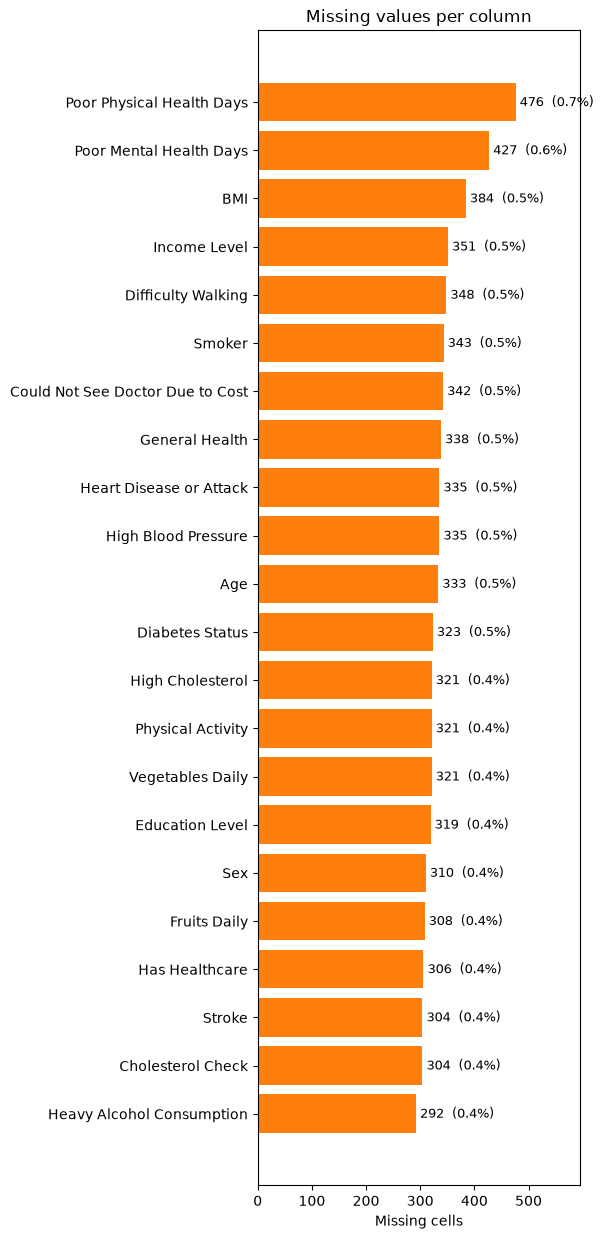

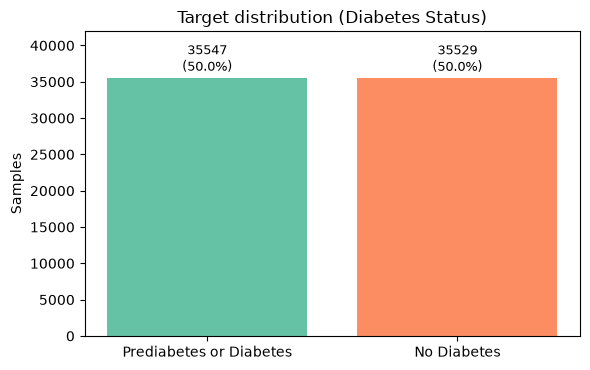

In [21]:
full_data = pd.read_csv(DATA_PATH)
print("Dataset shape:", full_data.shape)
display(full_data.head())

plot_missing_values(full_data)
plot_class_distribution(full_data[TARGET_COLUMN], title=f"Target distribution ({TARGET_COLUMN})")

## B.2 — Data cleaning (TODO)

Make `X` and `y` **model-ready**. Write your own code in the empty cell below. Things to look at:

1. **Duplicate rows** and rows **without a label** — what should happen to them?
2. **Useless columns** — identifiers (a different value in every row) carry no information.
3. **Categorical features** — the tree compares numbers (`x <= threshold`), so text columns must be converted to numbers. Think about *one-hot* encoding versus integer codes, and what to do with columns that have many categories.
4. **Missing values** — inspect them first. Missing *categories* can become their own category. For missing *numeric* values do **not** compute anything from the whole dataset here: statistics must come from the **Train** part only, so they are filled later, in **B.4**, after the split.
5. And everything you might sense in this dataset...

**After this cell the following variables must exist:**

| Variable | Requirement |
|---|---|
| `X` | `pandas.DataFrame`, **numeric columns only**, one row per sample, unique index (use `reset_index(drop=True)`), the target column is *not* in it |
| `y` | `pandas.Series` with the labels, same index as `X`, no missing values |

The next cell checks these requirements for you.

### Data cleaning

In [22]:
# TODO

print("Initial shape:", full_data.shape)

duplicate_count = full_data.duplicated().sum()
print("Duplicate records:", duplicate_count)


full_data = full_data.drop_duplicates().copy()


missing = full_data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("\nMissing values:")
print(missing)


full_data = full_data.dropna(
    subset=["Diabetes Status"]
).copy()

full_data = full_data.drop(
    columns=["id"],
    errors="ignore"
)
print("\nShape after cleaning:", full_data.shape)

Initial shape: (71399, 23)
Duplicate records: 707

Missing values:
Poor Physical Health Days           470
Poor Mental Health Days             420
BMI                                 380
Income Level                        350
Difficulty Walking                  345
Smoker                              340
Could Not See Doctor Due to Cost    335
Heart Disease or Attack             330
General Health                      330
High Blood Pressure                 330
Age                                 330
Physical Activity                   320
High Cholesterol                    320
Diabetes Status                     320
Education Level                     315
Vegetables Daily                    315
Sex                                 310
Fruits Daily                        305
Stroke                              300
Cholesterol Check                   300
Has Healthcare                      300
Heavy Alcohol Consumption           290
dtype: int64

Shape after cleaning: (70372, 22)


### Mapping categorical attribute

In [68]:
binary_mappings = {
    "High Blood Pressure": {"Yes": 1, "No": 0},
    "High Cholesterol": {"Yes": 1, "No": 0},
    "Smoker": {"Yes": 1, "No": 0},
    "Heavy Alcohol Consumption": {"Yes": 1, "No": 0},
    "Has Healthcare": {"Yes": 1, "No": 0},
    "Could Not See Doctor Due to Cost": {"Yes": 1, "No": 0},
    "Difficulty Walking": {"Yes": 1, "No": 0},
    "Physical Activity": {"Active": 1, "Inactive": 0},
    "Sex": {"Male": 1, "Female": 0},
}
for col, mapping in binary_mappings.items():
    if col in full_data.columns:
        full_data[col] = full_data[col].map(mapping)

full_data["General Health"] = full_data["General Health"].map({
    "Poor": 0,
    "Fair": 1,
    "Good": 2,
    "Very Good": 3,
    "Excellent": 4
}).astype(float)


### Outlier data

BMI values below 10: 0
BMI values above 80: 369
Age values below 0: 0
Age values above 120: 296

Outlier Detection Results:
                  Feature  IQR Lower Bound  IQR Upper Bound  IQR Outliers  Z-score Outliers
                      BMI             13.0             45.0          2457               416
  Poor Mental Health Days             -3.0              5.0         11686              4326
Poor Physical Health Days             -9.0             15.0         10510                 0
                      Age             22.5             98.5           978               296


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20264\644346872.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(full_data[col].dropna(), vert=False)


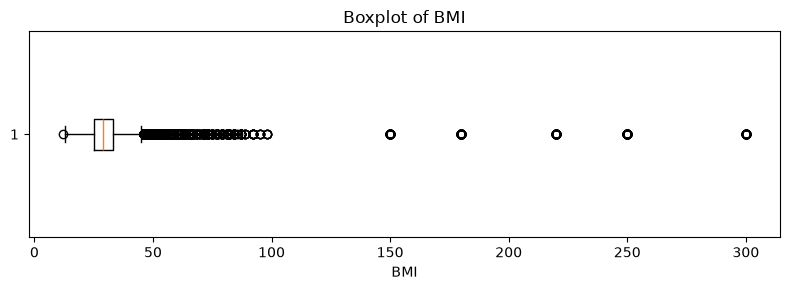

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20264\644346872.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(full_data[col].dropna(), vert=False)


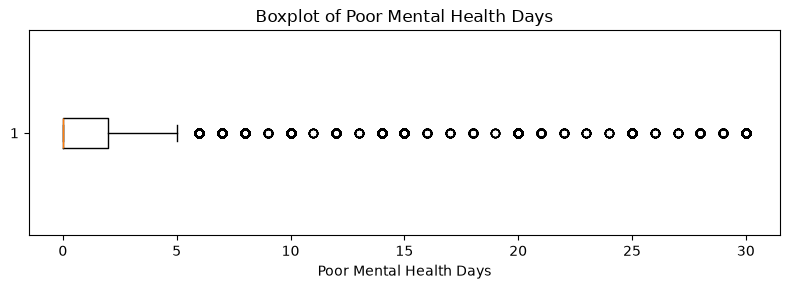

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20264\644346872.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(full_data[col].dropna(), vert=False)


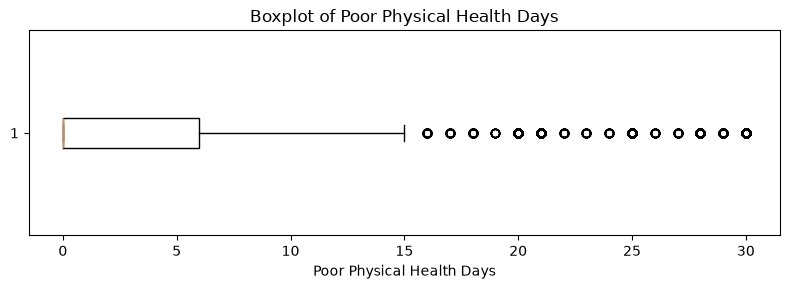

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_20264\644346872.py:64: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(full_data[col].dropna(), vert=False)


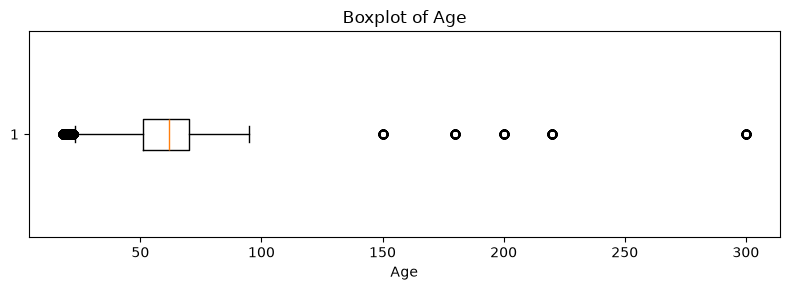

In [24]:
continuous_cols = [
    "BMI",
    "Poor Mental Health Days",
    "Poor Physical Health Days",
    "Age"
]


day_cols = [
    "Poor Mental Health Days",
    "Poor Physical Health Days"
]

for col in day_cols:
    full_data.loc[
        (full_data[col] < 0) | (full_data[col] > 30),
        col
    ] = float("nan")

print("BMI values below 10:", (full_data["BMI"] < 10).sum())
print("BMI values above 80:", (full_data["BMI"] > 80).sum())
print("Age values below 0:", (full_data["Age"] < 0).sum())
print("Age values above 120:", (full_data["Age"] > 120).sum())

outlier_results = []

for col in continuous_cols:
    data = full_data[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    iqr_count = (
        (data < lower_bound) | (data > upper_bound)
    ).sum()

    mean = data.mean()
    std = data.std()

    if std > 0:
        z_count = (((data - mean) / std).abs() > 3).sum()
    else:
        z_count = 0

    outlier_results.append({
        "Feature": col,
        "IQR Lower Bound": round(lower_bound, 2),
        "IQR Upper Bound": round(upper_bound, 2),
        "IQR Outliers": int(iqr_count),
        "Z-score Outliers": int(z_count)
    })

outlier_df = pd.DataFrame(outlier_results)
print("\nOutlier Detection Results:")
print(outlier_df.to_string(index=False))

for col in continuous_cols:
    plt.figure(figsize=(8, 3))

    plt.boxplot(full_data[col].dropna(), vert=False)

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


### Handling invalid values of outliers

In [25]:
# 1. BMI
invalid_bmi = full_data["BMI"] > 50

print("Invalid BMI values:", invalid_bmi.sum())
full_data.loc[invalid_bmi, "BMI"] = float("nan")


# 2. Poor Mental Health Days
invalid_mental = (full_data["Poor Mental Health Days"] < 0) | (full_data["Poor Mental Health Days"] > 30)
full_data.loc[invalid_mental, "Poor Mental Health Days"] = float("nan")
print("Invalid Poor Mental Health Days values:", invalid_mental.sum())
      
#3. Poor Physical Health Days
invalid_physical = (full_data["Poor Physical Health Days"] < 0) | (full_data["Poor Physical Health Days"] > 30)
full_data.loc[invalid_physical, "Poor Physical Health Days"] = float("nan")
print("Invalid Poor Physical Health Days values:", invalid_physical.sum())

# 3. Age
invalid_age = (full_data["Age"] < 18) | (full_data["Age"] > 100)
print("Invalid Age values:", invalid_age.sum())
full_data.loc[invalid_age, "Age"] = float("nan")


Invalid BMI values: 1209
Invalid Poor Mental Health Days values: 0
Invalid Poor Physical Health Days values: 0
Invalid Age values: 296


In [26]:
y = full_data["Diabetes Status"].copy()
X = full_data.drop(columns=["Diabetes Status"]).copy()
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

### Feature correlation heatmap

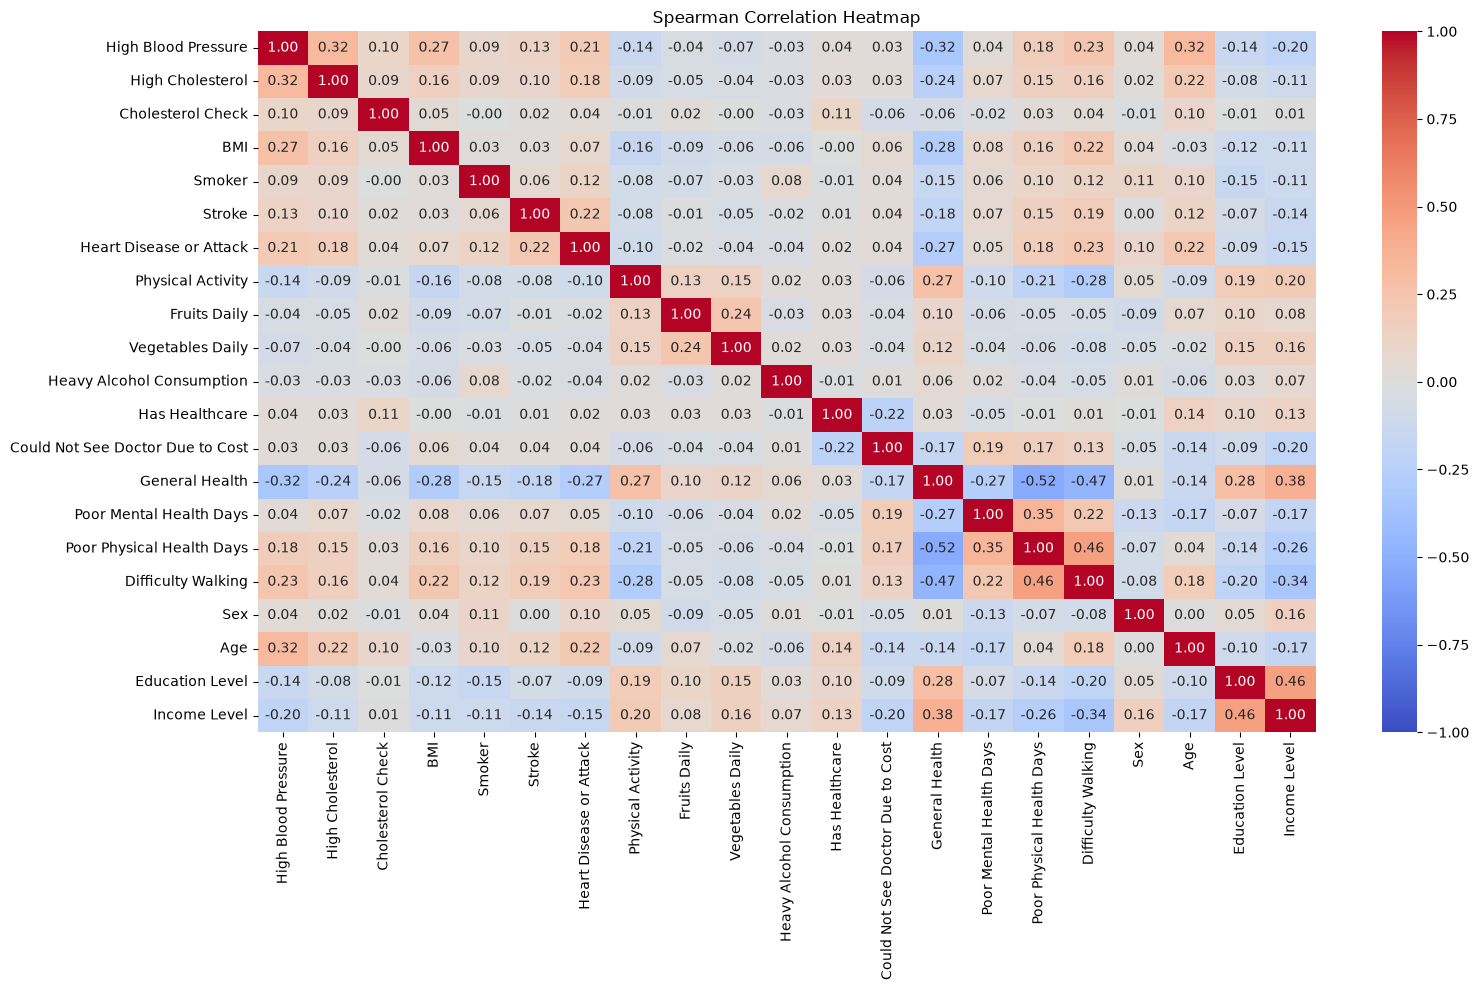

Series([], dtype: float64)


In [27]:
import seaborn as sns

corr = full_data.drop(
    columns=["Diabetes Status"]
).corr(method="spearman")

plt.figure(figsize=(16, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()


features = full_data.drop(columns=["Diabetes Status"])

corr = features.corr(method="spearman")

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

strong_corr = (
    upper.stack()
    .loc[lambda s: s.abs() > 0.7]
    .sort_values(key=abs, ascending=False)
)

print(strong_corr)

In [28]:
# Checks for your cleaned data — do not modify
assert isinstance(X, pd.DataFrame) and isinstance(y, pd.Series), "X must be a DataFrame and y a Series"
assert len(X) == len(y) and X.index.equals(y.index), "X and y must have the same rows / index"
assert X.index.is_unique, "The index must be unique — use reset_index(drop=True)"
assert all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes), "X must contain numeric columns only (encode the categorical ones)"
assert TARGET_COLUMN not in X.columns, "The target column must not be a feature"
assert not y.isna().any(), "y must not contain missing values"

FEATURE_NAMES = list(X.columns)
print("X:", X.shape, " y:", y.shape, "| classes:", sorted(y.unique().tolist()))
print("Missing numeric cells still in X (to be filled in B.4 with Train statistics):", int(X.isna().sum().sum()))

X: (70372, 21)  y: (70372,) | classes: ['No Diabetes', 'Prediabetes or Diabetes']
Missing numeric cells still in X (to be filled in B.4 with Train statistics): 8495


## B.3 — Train / Validation / Test split (no scikit-lear
n)
We split **once** into three parts: **70 % Train / 15 % Validation / 15 % Test**.
The split must be **stratified**: every part should keep (almost) the same class proportions as the full data — otherwise a rare class could end up missing from the Validation or Test set.

You will write one helper, `stratified_train_test_split`. It splits into *two* parts, so we call it twice:

```text
full data ──(test_size = 0.30)──► Train (70 %)  +  Temp (30 %)
Temp      ──(test_size = 0.50)──► Validation (15 %)  +  Test (15 %)
```

In [ ]:
def stratified_train_test_split(X, y, test_size=0.3, random_state=None):
    """
    Split X (DataFrame) and y (Series) into a train part and a test part so that the class
    proportions of y are (almost) the same in both parts. scikit-learn is NOT allowed.

    Steps:
        1. rng = np.random.RandomState(random_state)
        2. For every class c in np.unique(y):
             a. positions of the samples of this class:   idx = np.where(np.asarray(y) == c)[0]
             b. shuffle them:                              rng.shuffle(idx)
             c. the first  round(test_size * len(idx))  positions go to the test part, the rest to the train part
                (if the class has at least 2 samples, keep at least 1 sample on each side)
        3. Shuffle the collected train positions and test positions (rng.permutation) so the classes are mixed.
        4. Return the rows of X and y at those positions (use .iloc — the original index is kept).

    Returns (same order as scikit-learn):
        X_train, X_test, y_train, y_test
    """
    # TODO
    rng = np.random.RandomState(random_state)
    train_idx = []
    test_idx = []
    for c in np.unique(y):
        idx = np.where(np.asarray(y) == c)[0]
        rng.shuffle(idx)
        n_test = round(test_size * len(idx))
        if len(idx) >=2 :
            n_test = max(1 , min(n_test , len(idx) - 1))
        
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])
    
    train_idx = rng.permutation(train_idx)
    test_idx = rng.permutation(test_idx)
    
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]
    
    return X_train, X_test, y_train, y_test    
        
            
            

In [30]:
X_train, X_temp, y_train, y_temp = stratified_train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test     = stratified_train_test_split(X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

Train: (49260, 21) | Validation: (10556, 21) | Test: (10556, 21)


Split checks passed.


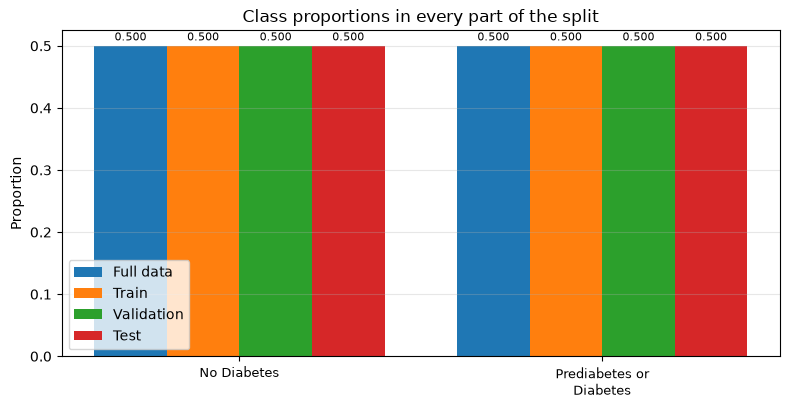

In [31]:
# Checks for your split — do not modify
n = len(X)
assert len(X_train) + len(X_val) + len(X_test) == n, "No sample may be lost or duplicated"
assert not (set(X_train.index) & set(X_val.index)) and not (set(X_train.index) & set(X_test.index)) \
       and not (set(X_val.index) & set(X_test.index)), "Train / Validation / Test must not overlap"
assert X_train.index.equals(y_train.index) and X_val.index.equals(y_val.index) and X_test.index.equals(y_test.index), \
       "X and y must stay aligned"
for name, part, frac in (("Train", X_train, 0.70), ("Validation", X_val, 0.15), ("Test", X_test, 0.15)):
    assert abs(len(part) / n - frac) < 0.02, f"{name} should contain about {frac:.0%} of the data"
overall = y.value_counts(normalize=True)
for name, part in (("Train", y_train), ("Validation", y_val), ("Test", y_test)):
    gap = (part.value_counts(normalize=True).reindex(overall.index, fill_value=0) - overall).abs().max()
    assert gap < 0.03, f"{name}: class proportions differ from the full data by {gap:.3f} — is the split stratified?"
print("Split checks passed.")
plot_class_proportions({"Full data": y, "Train": y_train, "Validation": y_val, "Test": y_test})

## B.4 — Baseline

Always predict the most frequent class of the **Train** set.

In [ ]:
# TODO
majority_class = y_train.mode()[0]
baseline_val_acc = accuracy_score_manual(y_val, np.full(len(y_val), majority_class))
print(f"Majority-class baseline (Validation): {baseline_val_acc:.3f}")

# Filling missing values
cols = [
    "High Blood Pressure", "High Cholesterol", "Cholesterol Check",
    "Smoker", "Stroke", "Heart Disease or Attack", "Physical Activity",
    "Fruits Daily", "Vegetables Daily", "Heavy Alcohol Consumption",
    "Has Healthcare", "Could Not See Doctor Due to Cost",
    "Difficulty Walking", "Sex", "General Health",
    "Education Level", "Income Level"
]
modes = X_train[cols].mode().iloc[0]
for X in [X_train, X_val, X_test]:
    X[cols] = X[cols].fillna(modes)

# # BMI
bmi_median = X_train["BMI"].median()
X_train["BMI"] = X_train["BMI"].fillna(bmi_median)
X_val["BMI"] = X_val["BMI"].fillna(bmi_median)
X_test["BMI"] = X_test["BMI"].fillna(bmi_median)

# #Poor Mental Health Days
median_value = X_train["Poor Mental Health Days"].median()
X_train["Poor Mental Health Days"] = X_train["Poor Mental Health Days"].fillna(median_value)
X_val["Poor Mental Health Days"] = X_val["Poor Mental Health Days"].fillna(median_value)
X_test["Poor Mental Health Days"] = X_test["Poor Mental Health Days"].fillna(median_value)

# #Poor Physical Health Days
median_Health = X_train["Poor Physical Health Days"].median()
X_train["Poor Physical Health Days"] = X_train["Poor Physical Health Days"].fillna(median_Health)
X_val["Poor Physical Health Days"] = X_val["Poor Physical Health Days"].fillna(median_Health)
X_test["Poor Physical Health Days"] = X_test["Poor Physical Health Days"].fillna(median_Health)

# #Age
median_Age = X_train["Age"].median()
X_train["Age"] =  X_train["Age"].fillna(median_Age)
X_val["Age"] =  X_val["Age"].fillna(median_Age)
X_test["Age"] =  X_test["Age"].fillna(median_Age)





Majority-class baseline (Validation): 0.500


### Questions (Part B)
1. What preprocessing did you apply, and why?
2. Why do we keep a separate Test set from the very beginning?
3. Look at the baseline accuracy. If your tree gets a value close to it, is the tree useful?
4. Why do we need part B.4? Can't we fill the missing values befor seperating?


جواب سوال های تئوری در گزارش داده شده است.

# Part C — Experiment 1: Let the Tree Grow

> **What happens if we put no restrictions on the tree?**

One `fit()` only.

In [ ]:
# TODO — Experiment 1: an UNRESTRICTED tree
#
# 1. Call run_experiment(make_config()) and store the result in a variable named  `unrestricted`.
#    (make_config() without arguments = no depth limit, min_samples_split=2, min_samples_leaf=1)
# 2. Print: the Train accuracy, the Validation accuracy, the majority baseline (baseline_val_acc)
#    and the complexity (depth, nodes, leaves).
#
# Hint: run_experiment returns a dict with the keys "train_acc", "val_acc", "depth", "nodes", "leaves", "tree".

unrestricted = run_experiment(make_config())


print(f"Train accuracy:      {unrestricted['train_acc']:.3f}")
print(f"Validation accuracy: {unrestricted['val_acc']:.3f}")
print(f"Majority baseline:   {baseline_val_acc:.3f}")

print(f"Tree depth:          {unrestricted['depth']}")
print(f"Number of nodes:     {unrestricted['nodes']}")
print(f"Number of leaves:    {unrestricted['leaves']}")


Train accuracy:      0.999
Validation accuracy: 0.656
Majority baseline:   0.500
Tree depth:          38
Number of nodes:     25503
Number of leaves:    12752


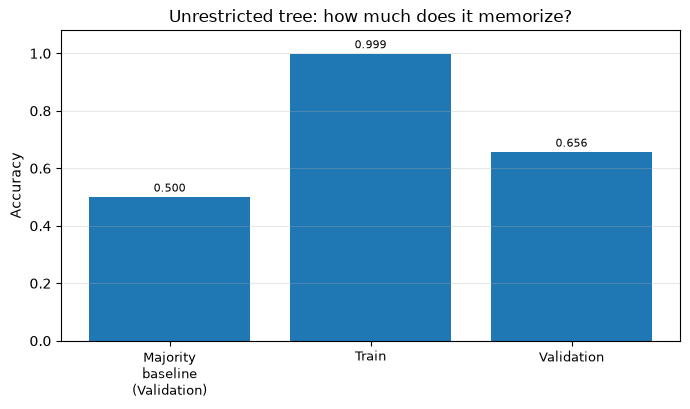

Train - Validation gap: 0.343


In [34]:
plot_bars(["Majority baseline\n(Validation)", "Train", "Validation"],
          {"Accuracy": [baseline_val_acc, unrestricted["train_acc"], unrestricted["val_acc"]]},
          title="Unrestricted tree: how much does it memorize?", ylim=(0, 1.08), figsize=(7, 4.2))
print(f"Train - Validation gap: {unrestricted['train_acc'] - unrestricted['val_acc']:.3f}")

### Questions (Part C)
1. Are Train and Validation accuracy close? What does the gap tell you?
2. How big did the tree become (nodes / leaves)? Does that seem reasonable for the amount of data?
3. Why can a tree reach ~100% Train accuracy so easily?


**✏️ Your answer:** *(double-click to edit)*

# Part D — Experiment 2: Underfitting vs Overfitting

> **Does a deeper tree always generalize better?**

Change **only** `max_depth`. The last value (∞) is the unrestricted tree from Part C.

In [ ]:
depth_values = [1, 2, 3, 4, 5, 6, 8, 10, float("inf")]      # float("inf") = no depth limit

# TODO — one experiment per depth value
#
# 1. For every d in depth_values call run_experiment(make_config(max_depth=d)).
#    Keep the list of results in a variable named  `depth_results`.
# 2. Convert it:   depth_df = to_df(depth_results)
#    (the plot in the next cell shows your results)

depth_results = []
for depth in depth_values:
    result = run_experiment(make_config(max_depth=depth))
    depth_results.append(result)

depth_df = to_df(depth_results)     

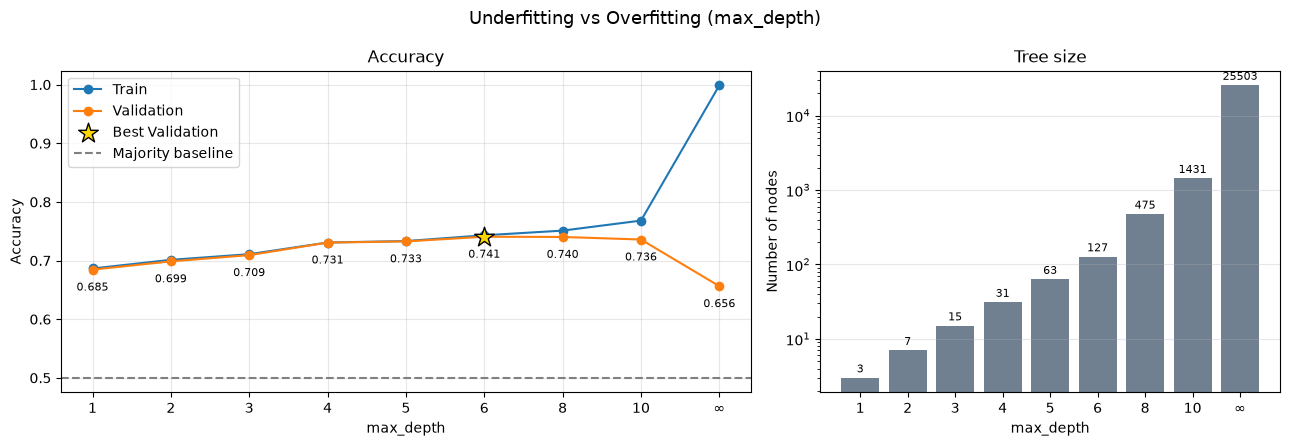

In [36]:
plot_sweep(depth_df, "max_depth", title="Underfitting vs Overfitting (max_depth)", baseline=baseline_val_acc)

### Questions (Part D)
1. Which depths look like **underfitting**? Which look like **overfitting**? How can you tell from the plot?
2. Is the deepest tree the best on Validation?
3. Can you choose the best model using only Train accuracy? Why not?


**✏️ Your answer:** *(double-click to edit)*

# Part E — Experiment 3: Pre-Pruning

> **Can we stop the tree from growing too much in the first place?**

`max_depth` already showed one way. Here we look at **two other knobs** (keep `max_depth = None`):

- `min_samples_split` — how many samples a node needs before it may be split.
- `min_samples_leaf` — how many samples every child must keep after a split (a split that would create a tiny leaf is not allowed).

In [ ]:
min_split_values = [2, 5, 10, 20, 50, 100]

# TODO — sweep min_samples_split (all other hyperparameters stay at their defaults)
#
# 1. For every m in min_split_values call run_experiment(make_config(min_samples_split=m)).
#    Keep the list in  `minsplit_results`  and build  `minsplit_df = to_df(minsplit_results)`.
#    (the plot in the next cell shows your results)

minsplit_results = []
for m in min_split_values:
    result = run_experiment(make_config(min_samples_split=m))
    minsplit_results.append(result)

minsplit_df = to_df(minsplit_results)    

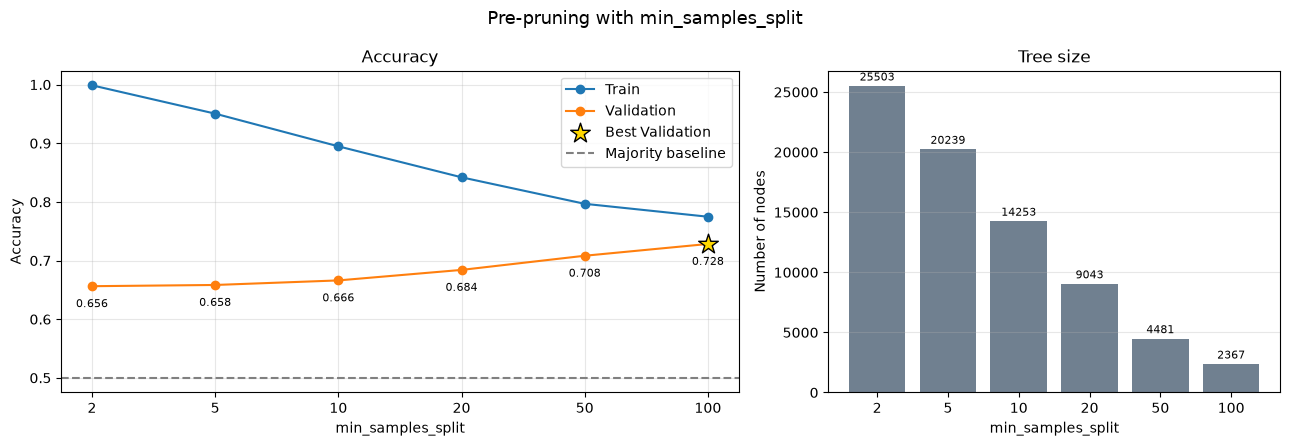

In [38]:
plot_sweep(minsplit_df, "min_samples_split", title="Pre-pruning with min_samples_split", baseline=baseline_val_acc)

In [ ]:
min_leaf_values = [1, 2, 5, 10, 20, 50]

# TODO — sweep min_samples_leaf (all other hyperparameters stay at their defaults)
minleaf_results = []
for m in min_leaf_values:
    result = run_experiment(make_config(min_samples_leaf=m))
    minleaf_results.append(result)
    
minleaf_df = to_df(minleaf_results)    
    
    

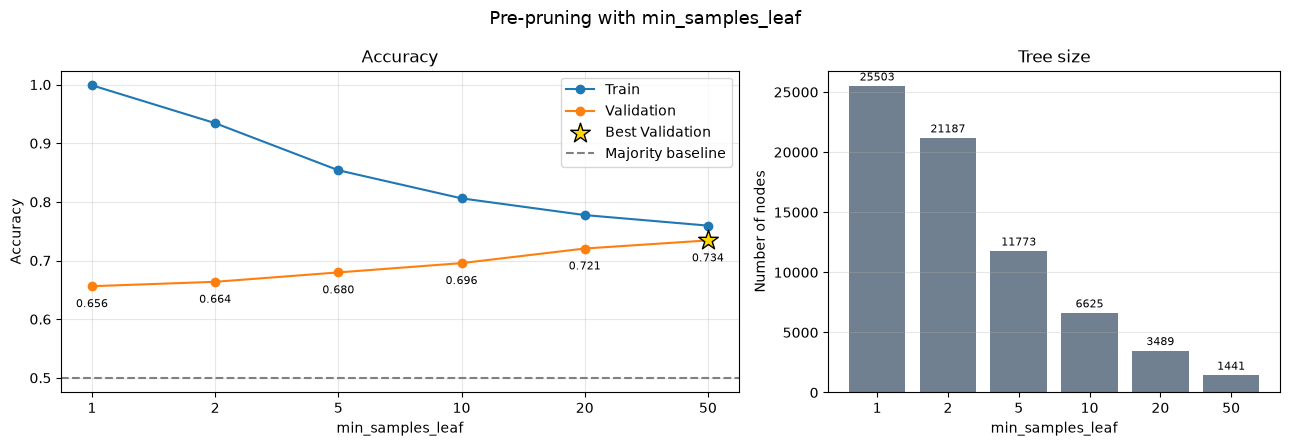

In [40]:
plot_sweep(minleaf_df, "min_samples_leaf", title="Pre-pruning with min_samples_leaf", baseline=baseline_val_acc)

In [ ]:
# TODO — pick ONE representative pre-pruned tree for the comparison in Part G
all_prepruning_results = minsplit_results + minleaf_results
best_val_acc = max(r["val_acc"] for r in all_prepruning_results)

ok_trees = [
    r for r in all_prepruning_results
    if r["val_acc"] >= best_val_acc - 0.01
]

pre_pruned = ok_trees[0]

for r in ok_trees:
    if r["nodes"] < pre_pruned["nodes"]:
        pre_pruned = r

print("Configuration:")
print({
    "criterion": pre_pruned["criterion"],
    "max_depth": pre_pruned["max_depth"],
    "min_samples_split": pre_pruned["min_samples_split"],
    "min_samples_leaf": pre_pruned["min_samples_leaf"]
})


print("\nMetrics:")
print(fmt({
    "train_acc": pre_pruned["train_acc"],
    "val_acc": pre_pruned["val_acc"],
    "depth": pre_pruned["depth"],
    "nodes": pre_pruned["nodes"],
    "leaves": pre_pruned["leaves"]
}))

Configuration:
{'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 50}

Metrics:
{'train_acc': 0.7596, 'val_acc': 0.7344, 'depth': 19, 'nodes': 1441, 'leaves': 721}


### Questions (Part E)
1. As `min_samples_split` increases, what happens to tree size and to the Train–Validation gap?
2. Did you find a much smaller tree with similar Validation accuracy?
3. At which moment of tree construction does Pre-Pruning act?
4. What is the difference between `min_samples_split` and `min_samples_leaf`? Which one controls the tree more strongly in your results?


**✏️ Your answer:** *(double-click to edit)*

# Part F — Experiment 4: Post-Pruning

> **If a tree has already grown too big, can we simplify it afterwards?**

```text
Train → Big tree → Post-Pruning → Smaller tree → Validation
```
Post-Pruning is usually done by testing, node by node, whether replacing a subtree with a leaf **does not hurt** accuracy on the Validation set.

In [ ]:
# TODO — Experiment 4: Post-Pruning

post_tree =DecisionTree(**make_config())
post_tree.fit(X_train , y_train)

before = snapshot(post_tree)
print("Before pruning:")
print(fmt(before))

post_prune(post_tree , X_val , y_val)
after = snapshot(post_tree)
print("After pruning:")
print(fmt(after))

removed_nodes = before["nodes"] - after["nodes"]
print("\n Nodes removed:" , removed_nodes)

post_pruned = {
    "train_acc" : after["train_acc"],
    "val_acc" : after["val_acc"],
    "depth" : after["depth"],
    "nodes" : after["nodes"],
    "leaves" : after["leaves"]
}

Before pruning:
{'train_acc': 0.9988, 'val_acc': 0.6563, 'depth': 38, 'nodes': 25503, 'leaves': 12752}
After pruning:
{'train_acc': 0.8727, 'val_acc': 0.7501, 'depth': 35, 'nodes': 10281, 'leaves': 5141}

 Nodes removed: 15222


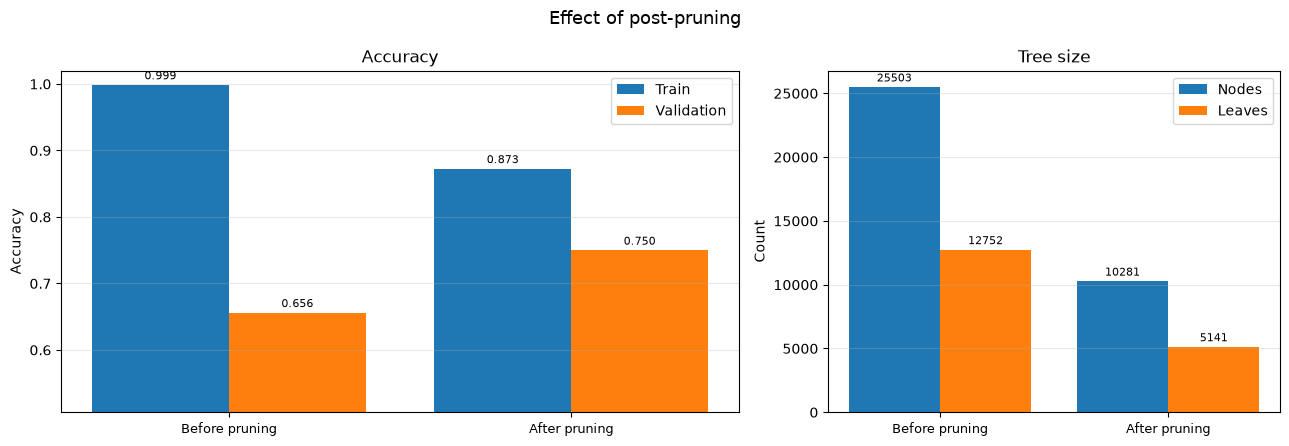

In [43]:
plot_before_after(before, after)

### Questions (Part F)
1. How many nodes were removed? How did Validation accuracy change?
2. Does a smaller tree necessarily mean a weaker model?
3. ⚠️ **Careful:** the Validation set was used to *decide* what to prune. Why is the Validation accuracy after pruning a slightly *optimistic* estimate? Which set gives an honest estimate?


**✏️ Your answer:** *(double-click to edit)*

# Part G — Experiment 5: No Pruning vs Pre-Pruning vs Post-Pruning

Collect the results from the previous parts in **one table**, and one plot: accuracy against tree size.

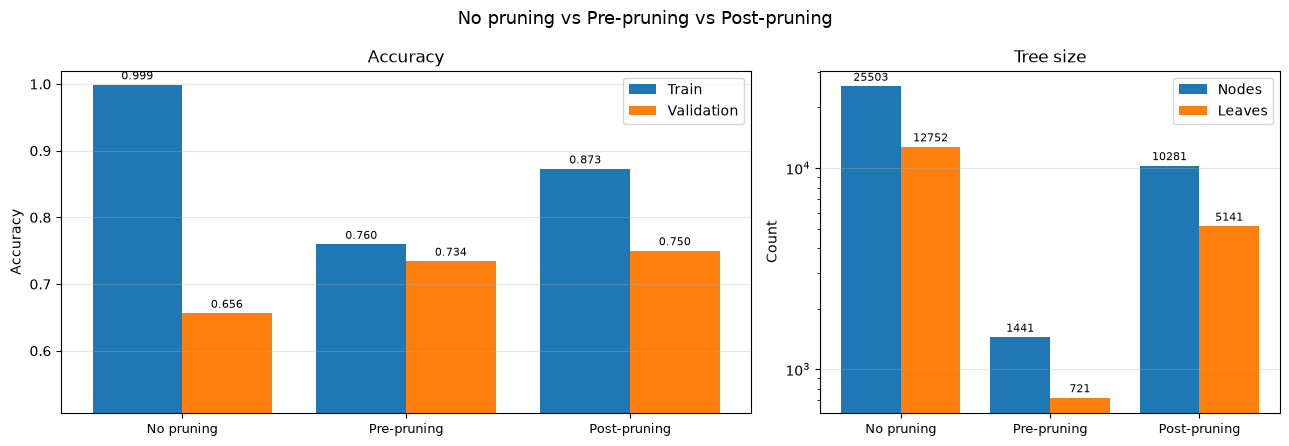

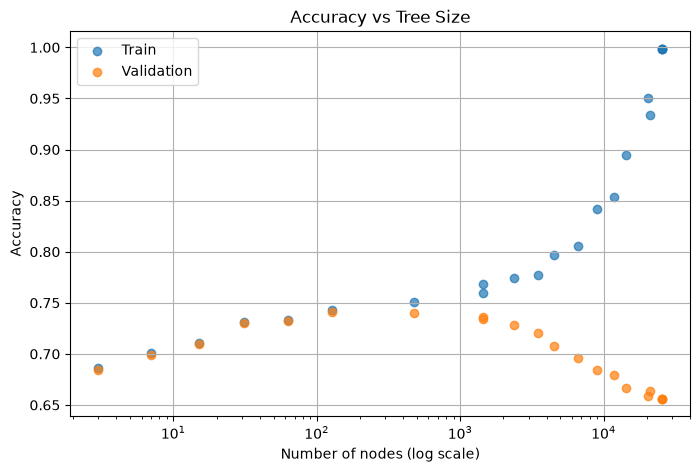

In [44]:
rows = [
    {"method": "No pruning",   **{k: unrestricted[k] for k in ("train_acc","val_acc","depth","nodes","leaves")}},
    {"method": "Pre-pruning",  **{k: pre_pruned[k]   for k in ("train_acc","val_acc","depth","nodes","leaves")}},
    {"method": "Post-pruning", **post_pruned},
]
comparison_df = pd.DataFrame(rows)

plot_model_comparison(comparison_df["method"].tolist(), comparison_df["train_acc"].tolist(), comparison_df["val_acc"].tolist(),
                      comparison_df["nodes"].tolist(), comparison_df["leaves"].tolist(),
                      title="No pruning vs Pre-pruning vs Post-pruning")

# Accuracy vs number of nodes for ALL trees built so far
pts = pd.concat([depth_df, minsplit_df, minleaf_df])
plt.figure(figsize=(8, 5))
plt.scatter(pts["nodes"], pts["train_acc"], label="Train", alpha=0.7)
plt.scatter(pts["nodes"], pts["val_acc"],   label="Validation", alpha=0.7)
plt.xscale("log"); plt.xlabel("Number of nodes (log scale)"); plt.ylabel("Accuracy")
plt.title("Accuracy vs Tree Size"); plt.legend(); plt.grid(True); plt.show()

### Questions (Part G)
1. Which method gave the simplest tree? Did it lose much Validation accuracy?
2. Conceptual difference between Pre-Pruning and Post-Pruning (when does each one act? which is cheaper?).
3. If two models have similar Validation accuracy, why should we prefer the smaller one?


**✏️ Your answer:** *(double-click to edit)*

# Part H — Experiment 6: Gini vs Information Gain

> **Do different splitting criteria really produce different trees?**

Same data, same restrictions — only `criterion` changes. (We use `max_depth = 4` so the printed trees are easy to compare.)

In [ ]:
# TODO — Gini vs Information Gain (same data, same restrictions, only `criterion` changes)
#
# 1. gain_res = run_experiment(make_config(criterion="entropy", max_depth=4))     # Information Gain
#    gini_res = run_experiment(make_config(criterion="gini",    max_depth=4))
#    (the next cell plots and compares them)

gain_res = run_experiment(make_config(criterion= "entropy" , max_depth=4))
gini_res = run_experiment(make_config(criterion="gini" , max_depth=4))

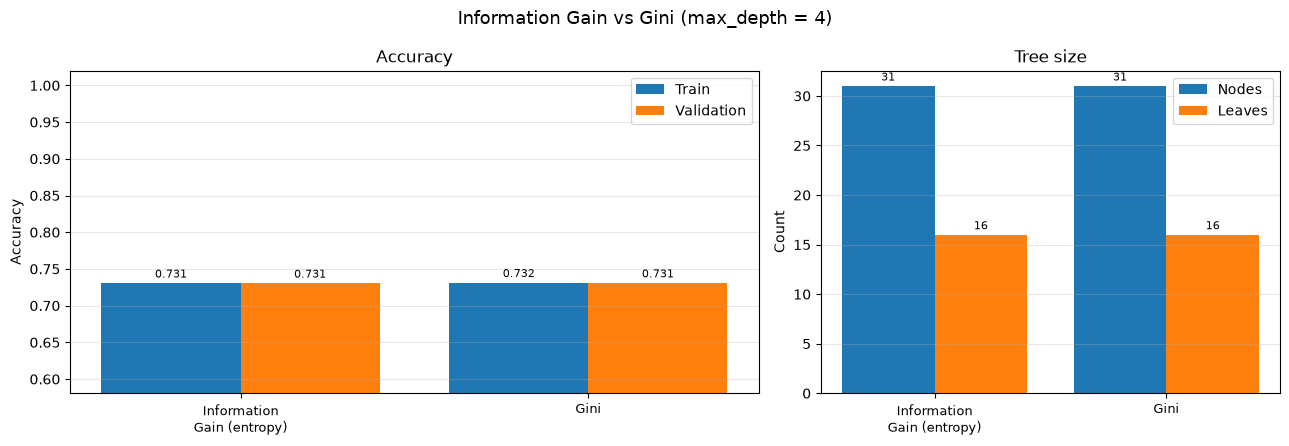

Root split (entropy): General Health <= 2.5
Root split (gini):    General Health <= 2.5
Validation predictions that are identical: 0.0%

===== Information Gain (entropy) =====
if General Health <= 2.500:
|   if High Blood Pressure <= 0.500:
|   |   if Age <= 39.500:
|   |   |   if General Health <= 1.500:
|   |   |   |   --> class = No Diabetes(samples = 384 , counts = {'No Diabetes': np.int64(231), 'Prediabetes or Diabetes': np.int64(153)})
|   |   |   else:   # General Health > 1.500
|   |   |   |   --> class = No Diabetes(samples = 1082 , counts = {'No Diabetes': np.int64(928), 'Prediabetes or Diabetes': np.int64(154)})
|   |   else:   # Age > 39.500
|   |   |   if BMI <= 27.500:
|   |   |   |   --> class = No Diabetes(samples = 3510 , counts = {'No Diabetes': np.int64(2108), 'Prediabetes or Diabetes': np.int64(1402)})
|   |   |   else:   # BMI > 27.500
|   |   |   |   --> class = Prediabetes or Diabetes(samples = 4381 , counts = {'No Diabetes': np.int64(1775), 'Prediabetes or Diabe

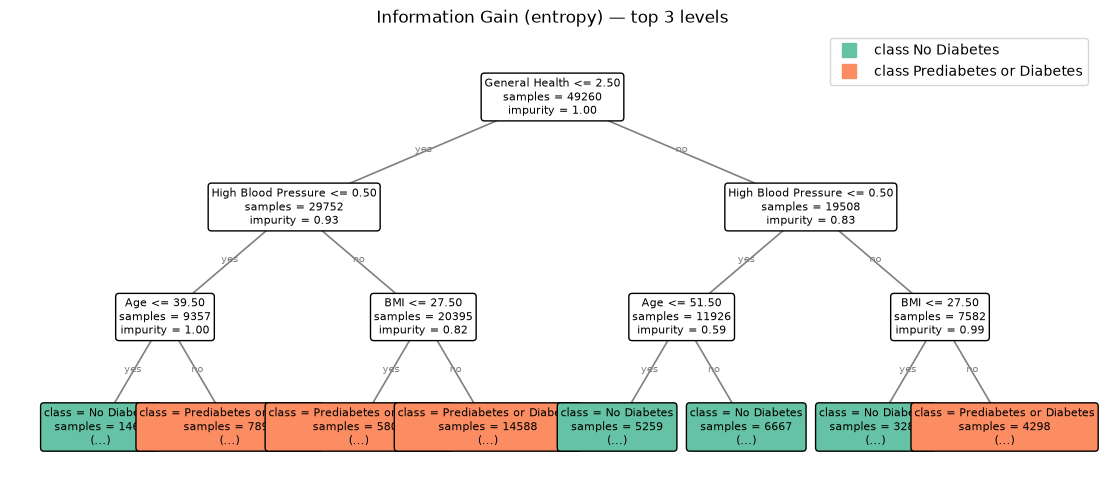

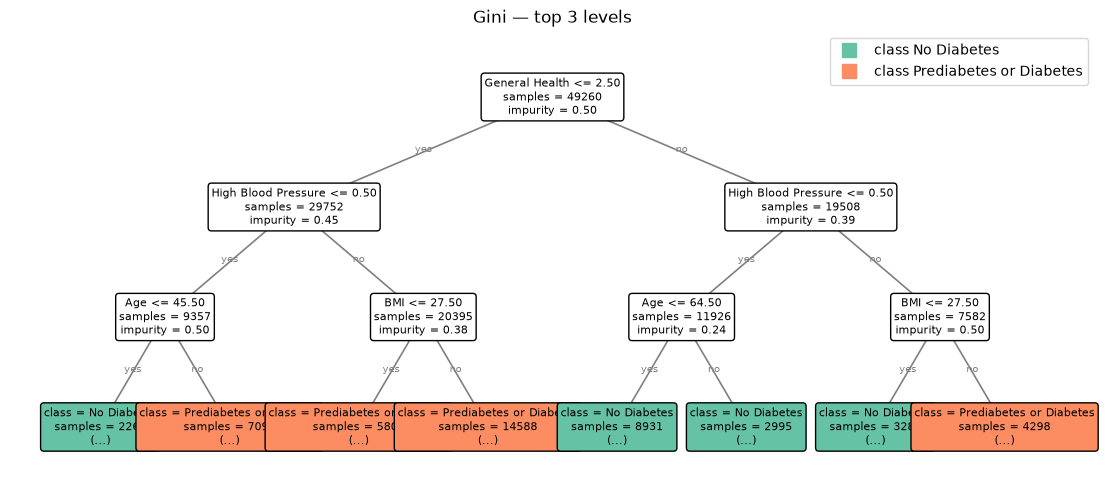

In [46]:
plot_model_comparison(["Information Gain\n(entropy)", "Gini"],
                      [gain_res["train_acc"], gini_res["train_acc"]], [gain_res["val_acc"], gini_res["val_acc"]],
                      [gain_res["nodes"], gini_res["nodes"]], [gain_res["leaves"], gini_res["leaves"]],
                      title="Information Gain vs Gini (max_depth = 4)")

# Do the two trees agree?
pred_gain = gain_res["tree"].predict(X_val)
pred_gini = gini_res["tree"].predict(X_val)
print("Root split (entropy):", FEATURE_NAMES[gain_res["tree"].root_.feature_index], "<=", round(gain_res["tree"].root_.threshold, 3))
print("Root split (gini):   ", FEATURE_NAMES[gini_res["tree"].root_.feature_index], "<=", round(gini_res["tree"].root_.threshold, 3))
print("Validation predictions that are identical:", f"{np.mean(pred_gain == pred_gini):.1%}")

print("\n===== Information Gain (entropy) ====="); print_tree(gain_res["tree"])
print("\n===== Gini ====="); print_tree(gini_res["tree"])

plot_tree(gain_res["tree"], max_depth=3, title="Information Gain (entropy) — top 3 levels", figsize=(14, 6))
plot_tree(gini_res["tree"], max_depth=3, title="Gini — top 3 levels", figsize=(14, 6))

# Part I — Experiment 7: Opening the Box (Explainability)

A big advantage of decision trees: **we can see why** they predict what they predict.
Use a small tree here (e.g. `max_depth = 4`) so the results are readable.

In [ ]:
# TODO — explain ONE prediction
#
# 1. explain_tree = a NEW DecisionTree built with make_config(max_depth=4), fitted on the TRAIN set.
# 2. sample = the first row of the Validation set  (X_val.iloc[0]).
# 3. Print the true label (y_val.iloc[0]), the predicted label (explain_tree.predict(X_val.iloc[[0]]))
#    and the feature values of the sample (print(sample.to_string())).
# 4. Print the decision path with  trace_path(explain_tree, sample).
explain_tree = DecisionTree(**make_config(max_depth=4))
explain_tree.fit(X_train , y_train)
sample = X_val.iloc[0]
print(f"True label : {y_val.iloc[0]} , Predicted label: {explain_tree.predict(X_val.iloc[[0]])}" )
print(sample.to_string())
trace_path(explain_tree , sample)


True label : No Diabetes , Predicted label: ['No Diabetes']
High Blood Pressure                  0.0
High Cholesterol                     1.0
Cholesterol Check                    1.0
BMI                                 24.0
Smoker                               0.0
Stroke                               0.0
Heart Disease or Attack              0.0
Physical Activity                    0.0
Fruits Daily                         1.0
Vegetables Daily                     1.0
Heavy Alcohol Consumption            0.0
Has Healthcare                       1.0
Could Not See Doctor Due to Cost     0.0
General Health                       4.0
Poor Mental Health Days              0.0
Poor Physical Health Days            0.0
Difficulty Walking                   0.0
Sex                                  0.0
Age                                 62.0
Education Level                      6.0
Income Level                         8.0
Step 1: General Health = 4 > 2.500 -> go right (node samples = 49260)
Step 2: H

'No Diabetes'

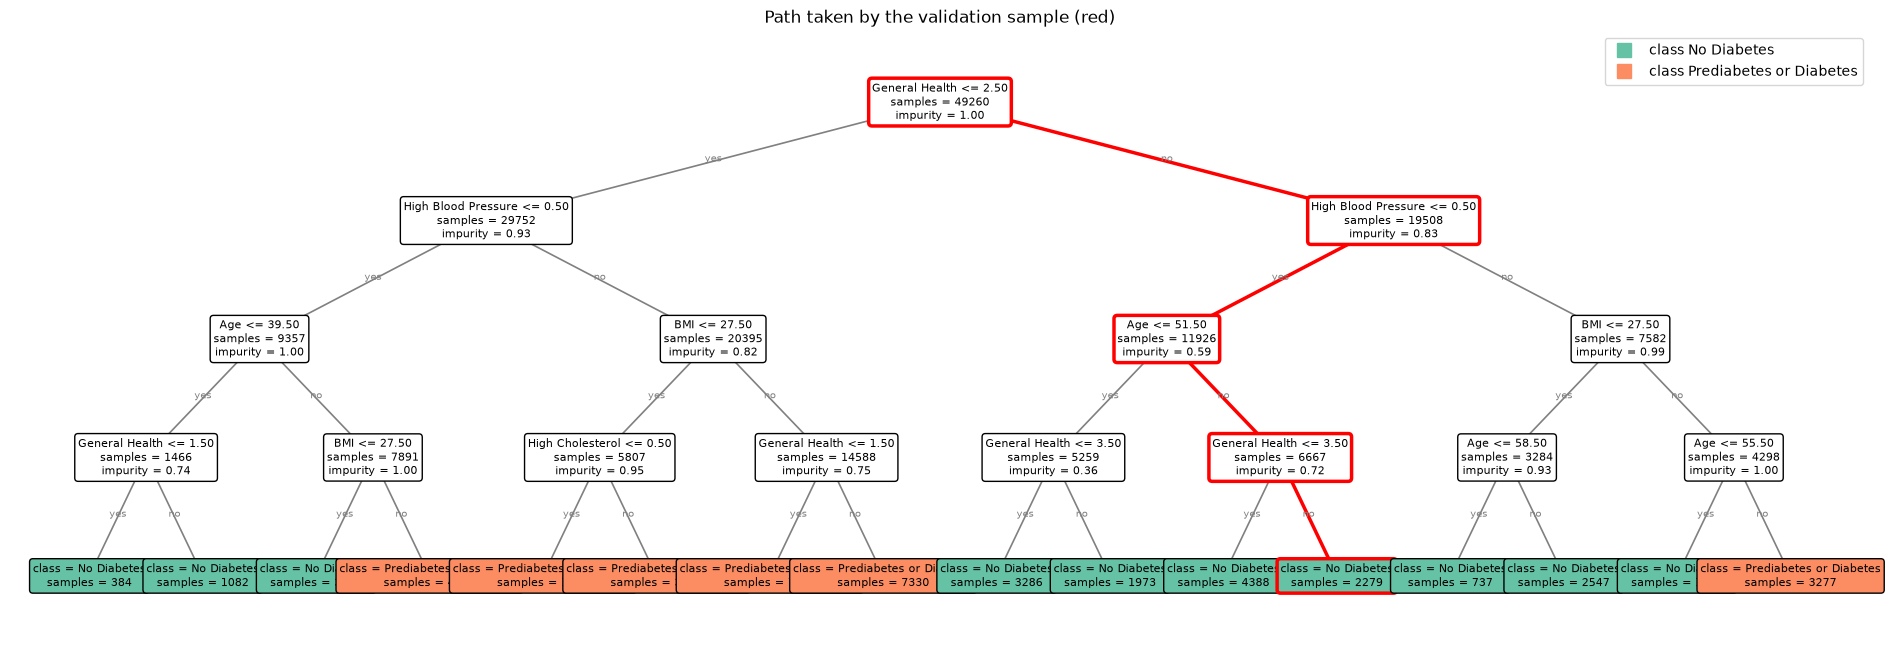

In [48]:
plot_tree(explain_tree, sample=sample, max_depth=4, title="Path taken by the validation sample (red)", figsize=(18, 8))

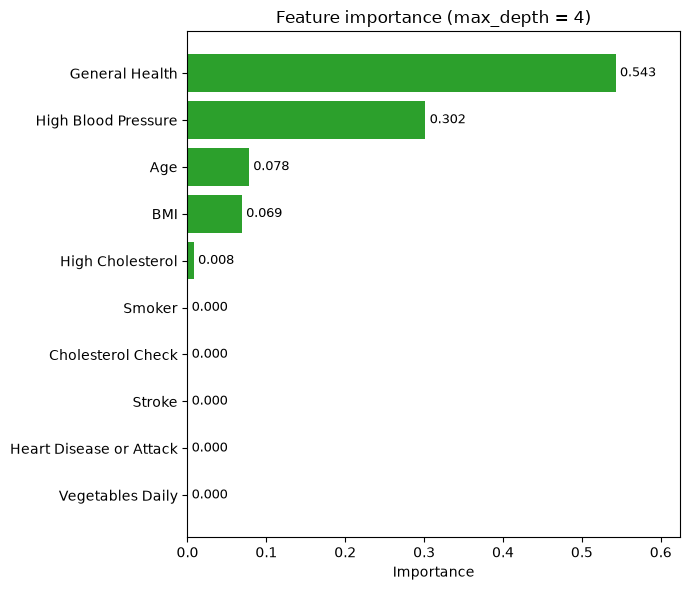

In [49]:
importance = feature_importance(explain_tree)
plot_feature_importance(importance, top=10, title="Feature importance (max_depth = 4)")

### Questions (Part I)
1. Which features/conditions decided this prediction?
2. Is the most important feature (overall) always used in every sample's path? Why / why not?


**✏️ Your answer:** *(double-click to edit)*

# Part J — Is One Validation Split Reliable? K-Fold Cross-Validation

So far we judged every tree on **one** Validation split. But that number depends on *which* samples happened to land there.

**K-Fold CV** (here K = 5):

```text
Dev set (Train + Validation) is cut into 5 folds
Round 1:  [VAL][ tr ][ tr ][ tr ][ tr ]
Round 2:  [ tr ][VAL][ tr ][ tr ][ tr ]
...                                       → 5 accuracies → mean ± std
```

Every sample is used for validation exactly once. The Test set stays outside of all this.

In [50]:
# Dev set = Train + Validation  (Test is still untouched)
X_dev = pd.concat([X_train, X_val]);  y_dev = pd.concat([y_train, y_val])

N_FOLDS = 5


def stratified_kfold_indices(y, n_splits=5, shuffle=True, random_state=None):
    """
    Stratified K-fold WITHOUT scikit-learn.
    Returns a list of n_splits pairs (train_idx, val_idx) of POSITIONS in y (use them with .iloc).
    Every class is spread evenly over the folds, so each fold keeps the class proportions of y.
    """
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    fold_of = np.empty(len(y), dtype=int)
    start = 0
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        if shuffle:
            rng.shuffle(idx)
        fold_of[idx] = (np.arange(len(idx)) + start) % n_splits      # deal the samples of this class over the folds
        start += len(idx)                                            # rotate, so fold sizes stay balanced
    return [(np.where(fold_of != k)[0], np.where(fold_of == k)[0]) for k in range(n_splits)]


folds = stratified_kfold_indices(y_dev, n_splits=N_FOLDS, random_state=RANDOM_STATE)   # the SAME folds are reused for every configuration
print("Fold sizes (validation part):", [len(v) for _, v in folds])

Fold sizes (validation part): [11964, 11963, 11963, 11963, 11963]


In [ ]:
def cross_validate(config):
    """
    K-fold cross-validation for ONE configuration.

    For every (train_idx, val_idx) in `folds`:
        1. build a NEW DecisionTree(**config)
        2. fit it on  X_dev.iloc[train_idx], y_dev.iloc[train_idx]
        3. compute the accuracy on the fold's training part and on its validation part
           (accuracy_score_manual)
        4. record the number of nodes of the tree (tree.n_nodes_)

    Return a dict with the keys:
        "cv_train_acc": mean training accuracy over the folds
        "cv_val_acc"  : mean validation accuracy over the folds
        "cv_val_std"  : standard deviation (np.std) of the validation accuracies
        "cv_nodes"    : mean number of nodes
        "fold_accs"   : list with the validation accuracy of each fold
    """
    # TODO
    train_accs = []
    val_accs = []
    node_counts = []
    fold_accs = []
    for train_idx , val_idx in folds:
        tree = DecisionTree(**config)
        X_train_fold = X_dev.iloc[train_idx]
        y_train_fold = y_dev.iloc[train_idx]

        X_val_fold = X_dev.iloc[val_idx]
        y_val_fold = y_dev.iloc[val_idx]
        
        tree.fit(X_train_fold , y_train_fold)
        
        train_pred = tree.predict(X_train_fold)
        val_pred = tree.predict(X_val_fold)
        
        train_acc = accuracy_score_manual(y_train_fold , train_pred)
        val_acc = accuracy_score_manual(y_val_fold , val_pred)
        
        train_accs.append(train_acc)
        val_accs.append(val_acc)
        
        node_counts.append(tree.n_nodes_)
        
        fold_accs.append(val_acc)
    
    return {
        "cv_train_acc": np.mean(train_accs),
        "cv_val_acc": np.mean(val_accs),
        "cv_val_std": np.std(val_accs),
        "cv_nodes": np.mean(node_counts),
        "fold_accs": fold_accs
    }    
        
        

Time for 10 fits: 529.5s
Unrestricted: mean = 0.6582, std = 0.0021
Pre-pruned (depth=5, min_samples_split=10): mean = 0.7306, std = 0.0040


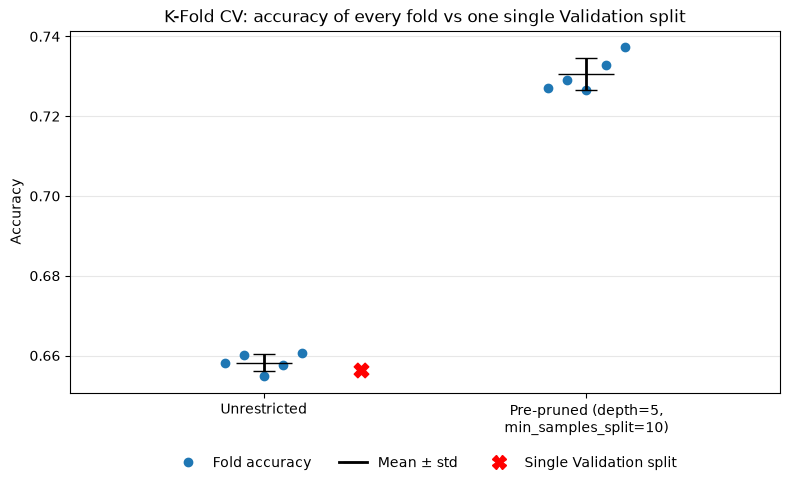

In [52]:
demo_configs = {"Unrestricted": make_config(),
                "Pre-pruned (depth=5, min_samples_split=10)": make_config(max_depth=5, min_samples_split=10)}

t0 = time.time()
cv_demo = {name: cross_validate(cfg) for name, cfg in demo_configs.items()}
print(f"Time for {len(demo_configs) * N_FOLDS} fits: {time.time() - t0:.1f}s")
for name, cv in cv_demo.items():
    print(f"{name}: mean = {cv['cv_val_acc']:.4f}, std = {cv['cv_val_std']:.4f}")

plot_cv_folds(cv_demo, single_split={"Unrestricted": unrestricted["val_acc"]},
              title="K-Fold CV: accuracy of every fold vs one single Validation split")

### Questions (Part J)
1. How much do the fold accuracies vary for the same configuration? What does this say about trusting a single split?
2. Which model has the smaller `std` (more stable)? Why might that be?
3. Why must every configuration be evaluated on the **same** folds?


**✏️ Your answer:** *(double-click to edit)*

# Part K — Hyperparameter Tuning: Grid Search + K-Fold CV

> **Grid Search:** try *every* combination in a grid, score each with K-Fold CV, keep the best.

```text
for every (criterion, max_depth, min_samples_split):
    K-fold CV  →  mean validation accuracy ± std, mean tree size
pick the best trade-off  →  refit on the whole Dev set
```
Total fits = (number of combinations) × K. Keep the grid small — the printed time estimate will help you.

In [ ]:
from itertools import product

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [4, 5, 6, None],
    "min_samples_split": [50, 75, 100],
    "min_samples_leaf": [40, 50]
}
# You may add more values or `min_samples_leaf` (see Part E) — but watch the runtime!

combos = list(product(*param_grid.values()))
print(f"{len(combos)} combinations x {N_FOLDS} folds = {len(combos) * N_FOLDS} fits")

t0 = time.time()
cross_validate(make_config(max_depth=5, min_samples_split=10))          # time a single CV round
print(f"Estimated total time: ~{(time.time() - t0) * len(combos) / 60:.1f} min")

48 combinations x 5 folds = 240 fits
Estimated total time: ~121.8 min


In [ ]:
# TODO — run the grid search
#
# For every (criterion, depth, min_s) in `combos`:
#     cv = cross_validate(make_config(criterion=criterion, max_depth=depth, min_samples_split=min_s))
#     store one row:  {"criterion", "max_depth", "min_samples_split"}  +  every entry of cv EXCEPT "fold_accs"
#
# Then:
#     grid_df = pd.DataFrame(rows)
#     grid_df["gap"] = cv_train_acc - cv_val_acc            # overfitting indicator
#     (the next cell plots the 10 best configurations)
#
# The heatmap cell below needs these columns:  criterion, max_depth, min_samples_split, cv_val_acc.

rows = []
for criterion , depth , min_s , min_l  in combos:
    cv = cross_validate(make_config(criterion=criterion , max_depth=depth , min_samples_split=min_s , min_samples_leaf=min_l))
    row = {
    "criterion": criterion,
    "max_depth": depth,
    "min_samples_split": min_s,
    "min_samples_leaf" : min_l,
    "cv_train_acc": cv["cv_train_acc"],
    "cv_val_acc": cv["cv_val_acc"],
    "cv_val_std": cv["cv_val_std"],
    "cv_nodes": cv["cv_nodes"]
}
    rows.append(row)

grid_df = pd.DataFrame(rows)    
grid_df["gap"] = grid_df["cv_train_acc"] - grid_df["cv_val_acc"]
    
    

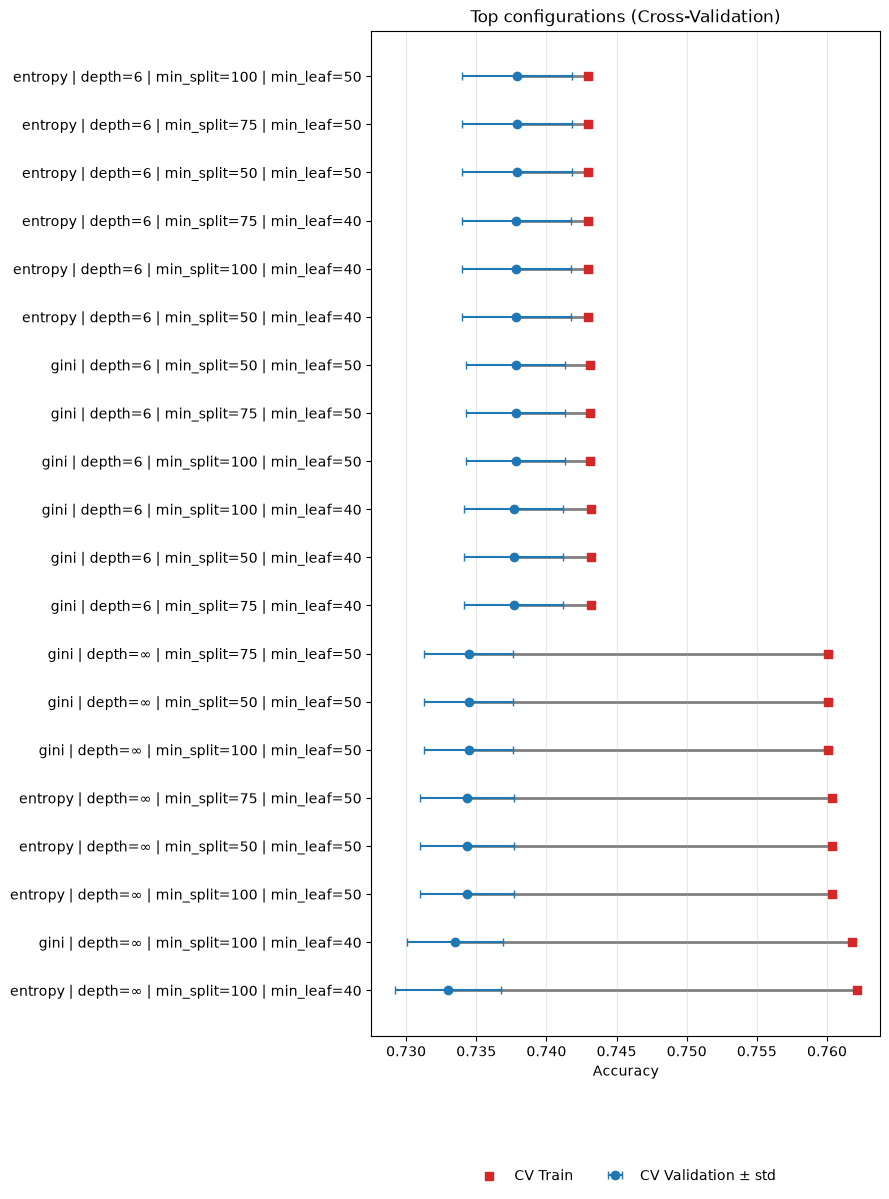

In [69]:
plot_top_configs(grid_df, k=20)

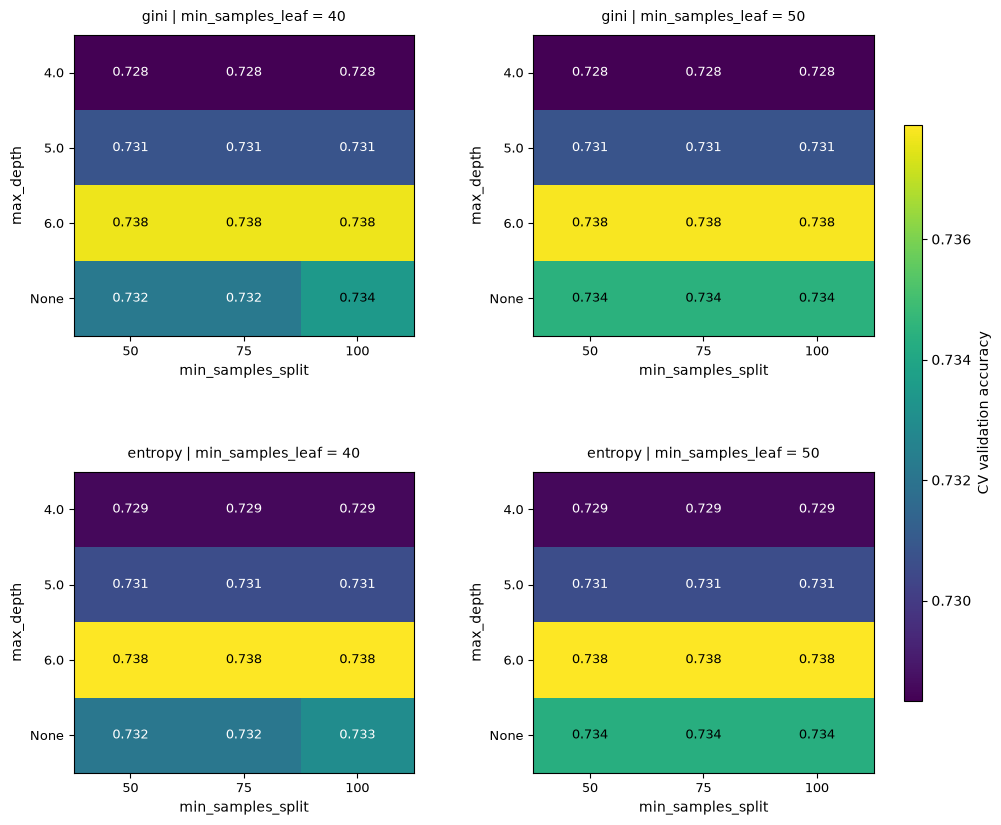

In [57]:
leaf_values = param_grid["min_samples_leaf"]
criteria = param_grid["criterion"]

fig, axes = plt.subplots(
    nrows=len(criteria),
    ncols=len(leaf_values),
    figsize=(5 * len(leaf_values), 4.5 * len(criteria)),
    squeeze=False,
    sharey=False
)

vmin = grid_df["cv_val_acc"].min()
vmax = grid_df["cv_val_acc"].max()

for i, crit in enumerate(criteria):
    for j, leaf in enumerate(leaf_values):
        ax = axes[i, j]

        subset = grid_df[
            (grid_df["criterion"] == crit) &
            (grid_df["min_samples_leaf"] == leaf)
        ]

        pivot = subset.pivot(
            index="max_depth",
            columns="min_samples_split",
            values="cv_val_acc"
        )

    
        pivot = pivot.sort_index()
        pivot = pivot.reindex(sorted(pivot.columns), axis=1)

        im = ax.imshow(
            pivot.values,
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            aspect="auto",
            interpolation="nearest"
        )

        ax.set_xticks(range(len(pivot.columns)))
        ax.set_xticklabels(pivot.columns)

        ax.set_yticks(range(len(pivot.index)))
        ax.set_yticklabels([
            "None" if pd.isna(d) else str(d)
            for d in pivot.index
        ])

        ax.set_xlabel("min_samples_split")
        ax.set_ylabel("max_depth")
        ax.set_title(
            f"{crit} | min_samples_leaf = {leaf}",
            fontsize=10,
            pad=10
        )

       
        for r in range(pivot.shape[0]):
            for c in range(pivot.shape[1]):
                value = pivot.iloc[r, c]

                if pd.notna(value):
                    color = "white" if value < (vmin + vmax) / 2 else "black"
                    ax.text(
                        c, r, f"{value:.3f}",
                        ha="center",
                        va="center",
                        fontsize=9,
                        color=color
                    )

        ax.tick_params(axis="both", labelsize=9)

fig.subplots_adjust(
    left=0.08,
    right=0.88,
    bottom=0.10,
    top=0.92,
    wspace=0.35,
    hspace=0.45
)

cbar_ax = fig.add_axes([0.91, 0.18, 0.018, 0.64])
fig.colorbar(im, cax=cbar_ax, label="CV validation accuracy")

plt.show()

In [ ]:
TOLERANCE = 0.01

# TODO — "simplest model that is almost as good as the best" rule
#
# 1. best = the highest cv_val_acc in grid_df
# 2. candidates = the rows of grid_df with cv_val_acc >= best - TOLERANCE
# 3. suggested = among the candidates, the row with the fewest nodes (cv_nodes);
#    break ties with the smaller max_depth.
# 4. print best, the number of candidates and the suggested configuration
#    (criterion, max_depth, min_samples_split, cv_val_acc ± cv_val_std, cv_nodes)
#
# `suggested` must be ONE row (a pandas Series): Part L reads suggested["criterion"], ["max_depth"],
# ["min_samples_split"], ["cv_val_acc"] and ["cv_val_std"].

best = grid_df["cv_val_acc"].max()
candidates = grid_df[
    grid_df["cv_val_acc"] >= best - TOLERANCE
    ]

candidates["max_depth"] = candidates["max_depth"].fillna(float("inf"))
candidates = candidates.sort_values(
    by=["cv_nodes" , "max_depth"],
    ascending=True
    )
suggested =candidates.iloc[0]


print("Best CV accuracy:", round(float(best), 4))
print("Number of candidates:", len(candidates))

print("Suggested configuration:")
print("criterion:", suggested["criterion"])
print("max_depth:", suggested["max_depth"])
print("min_samples_split:", suggested["min_samples_split"])
print("min_samples_leaf:", suggested["min_samples_leaf"])
print(f"cv_val_acc: {suggested['cv_val_acc']:.4f} ± {suggested['cv_val_std']:.4f}")
print("cv_nodes:", suggested["cv_nodes"])

Best CV accuracy: 0.7379
Number of candidates: 48
Suggested configuration:
criterion: gini
max_depth: 4.0
min_samples_split: 50
min_samples_leaf: 40
cv_val_acc: 0.7283 ± 0.0047
cv_nodes: 31.0


### Questions (Part K)
1. Look at the heatmaps: which region of the grid is best? What happens at very large depth with small `min_samples_split`?
2. Compare `cv_train_acc` and `cv_val_acc` (column `gap`) for the top configurations. Which are overfitting?
3. Are the top configurations really different, given the `cv_val_std` values you saw in Part J?
4. Which configuration do you choose, and why? (You may follow the rule above or argue for another one.)
5. Why is this more trustworthy than picking the best point on a single Validation split?


**✏️ Your answer:** *(double-click to edit)*

# Part L — Final Model, Test Evaluation & Visualization

Refit the chosen configuration on the whole **Dev set** (Train + Validation), then evaluate on the Test set.

> ### ⚠️ The Test set is used **only here, only once**.

In [ ]:
# TODO — final model

FINAL_CRITERION = suggested["criterion"]
FINAL_MAX_DEPTH = suggested["max_depth"]
FINAL_MIN_SAMPLES_SPLIT = suggested["min_samples_split"]
FINAL_MIN_SAMPLES_LEAF = suggested["min_samples_leaf"]

final_config = make_config(
    criterion=FINAL_CRITERION,
    max_depth=FINAL_MAX_DEPTH,
    min_samples_split=FINAL_MIN_SAMPLES_SPLIT,
    min_samples_leaf=FINAL_MIN_SAMPLES_LEAF
)


final_tree = DecisionTree(**final_config)
final_tree.fit(X_dev, y_dev)


y_dev_pred = final_tree.predict(X_dev)
dev_acc = accuracy_score_manual(y_dev, y_dev_pred)


cv = cross_validate(final_config)


model_complexity = complexity(final_tree)

print("Final configuration:", final_config)
print("Dev accuracy:", round(dev_acc, 4))
print(
    "CV validation accuracy:",
    f"{cv['cv_val_acc']:.4f} +/- {cv['cv_val_std']:.4f}"
)
print("Model complexity:", model_complexity)

Final configuration: {'criterion': 'gini', 'max_depth': np.float64(4.0), 'min_samples_split': np.int64(50), 'min_samples_leaf': np.int64(40)}
Dev accuracy: 0.7315
CV validation accuracy: 0.7283 +/- 0.0047
Model complexity: {'depth': 4, 'nodes': 31, 'leaves': 16}


In [60]:
# TODO — the ONLY place where the Test set is used
#
# test_pred = predictions of final_tree on X_test
# test_acc  = accuracy of those predictions (accuracy_score_manual)
test_pred = final_tree.predict(X_test)    
test_acc  = accuracy_score_manual(y_test , test_pred)

FINAL TEST ACCURACY: 0.7265


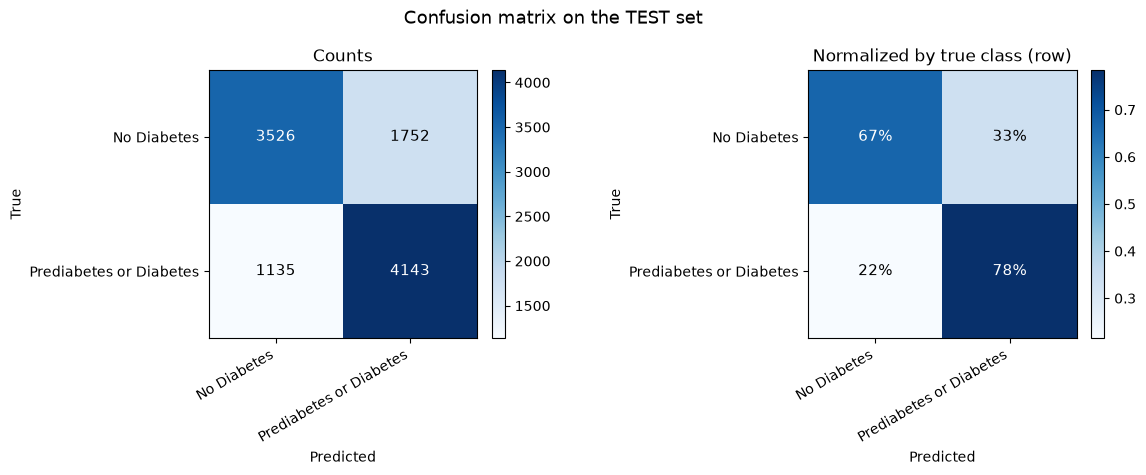

In [61]:
print("=" * 40)
print(f"FINAL TEST ACCURACY: {test_acc:.4f}")
print("=" * 40)

all_classes = sorted(set(np.asarray(y_test)))
cm = plot_confusion_matrix(y_test, test_pred, classes=all_classes, title="Confusion matrix on the TEST set")

## Beyond accuracy: Precision, Recall and F1

The **confusion matrix** above shows *which* mistakes the tree makes. **Accuracy** squeezes everything into one number and treats every mistake the same — which can be misleading, especially when the classes are **imbalanced** (a model that always predicts the majority class already looks "accurate", as you saw with the baseline).
Three metrics look at the mistakes **class by class**.

For a given class $c$ we pretend that $c$ is the **positive** class and all other classes together are the negative class. Then, for the Test set:

| Symbol | Meaning | In the confusion matrix (rows = true, columns = predicted) |
|---|---|---|
| **TP** (true positives) | true class is $c$, predicted $c$ | the diagonal cell of $c$ |
| **FP** (false positives) | true class is *not* $c$, but predicted $c$ | the rest of the **column** of $c$ |
| **FN** (false negatives) | true class is $c$, but predicted something else | the rest of the **row** of $c$ |

### Precision — "When the tree says $c$, how often is it right?"

$$\text{precision}_c = \frac{TP}{TP + FP}$$

It is the fraction of the samples **predicted** as $c$ that really are $c$. Low precision means many **false alarms**. It matters when a wrong positive prediction is expensive (e.g. sending an expensive compensation voucher to a passenger who was in fact satisfied).

### Recall — "Of all real $c$ samples, how many did the tree find?"

$$\text{recall}_c = \frac{TP}{TP + FN}$$

It is the fraction of the samples that **truly** are $c$ and were found. Low recall means many **misses**. It matters when missing a positive is expensive (e.g. never noticing a dissatisfied passenger who then leaves). Recall is exactly the diagonal of the *row-normalized* heatmap on the right of the confusion matrix.

### F1-score — one number that needs both

$$F1_c = \frac{2 \cdot \text{precision}_c \cdot \text{recall}_c}{\text{precision}_c + \text{recall}_c}$$

The **harmonic mean** of precision and recall. Unlike the ordinary average it is low whenever *one* of the two is low: precision = 1.0 and recall = 0.01 give an average of about 0.5, but an F1 of only about 0.02.

### One number for all classes

| Average | How it is computed | Use it when |
|---|---|---|
| **macro** | plain mean of the per-class values | every class is equally important (rare classes count as much as frequent ones) |
| **weighted** | mean weighted by the **support** (number of true samples of each class) | you care about the overall behaviour on the real class distribution |

> **Convention:** if a denominator is 0 (e.g. the tree *never* predicts a class, so $TP + FP = 0$), define the metric as `0.0`.

Next, you compute all of them **yourself from the Test predictions** (no scikit-learn).

In [ ]:
# TODO — precision, recall and F1 for every class, computed from the TEST set
y_test = np.asarray(y_test).ravel()
test_pred = np.asarray(test_pred).ravel()
rows = []
for c in all_classes:
    
    TP = np.sum((y_test == c) & (test_pred == c))
    FP = np.sum((y_test != c) & (test_pred == c))
    FN = np.sum((y_test == c) & (test_pred != c))
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1 =( 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0 ) 
    support = TP + FN
    
    rows.append({
        "class": c,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support
    })

report_df = pd.DataFrame(rows).set_index("class")

macro_avg = report_df[["precision", "recall", "f1"]].mean()

weighted_avg = (
    report_df[["precision", "recall", "f1"]]
    .multiply(report_df["support"], axis=0)
    .sum()
    / report_df["support"].sum()
)

avg_df = pd.DataFrame(
    [macro_avg, weighted_avg],
    index=["macro avg", "weighted avg"]
)

print(report_df.round(3))
print(avg_df.round(3))



                         precision  recall     f1  support
class                                                     
No Diabetes                  0.756   0.668  0.710     5278
Prediabetes or Diabetes      0.703   0.785  0.742     5278
              precision  recall     f1
macro avg          0.73   0.727  0.726
weighted avg       0.73   0.727  0.726


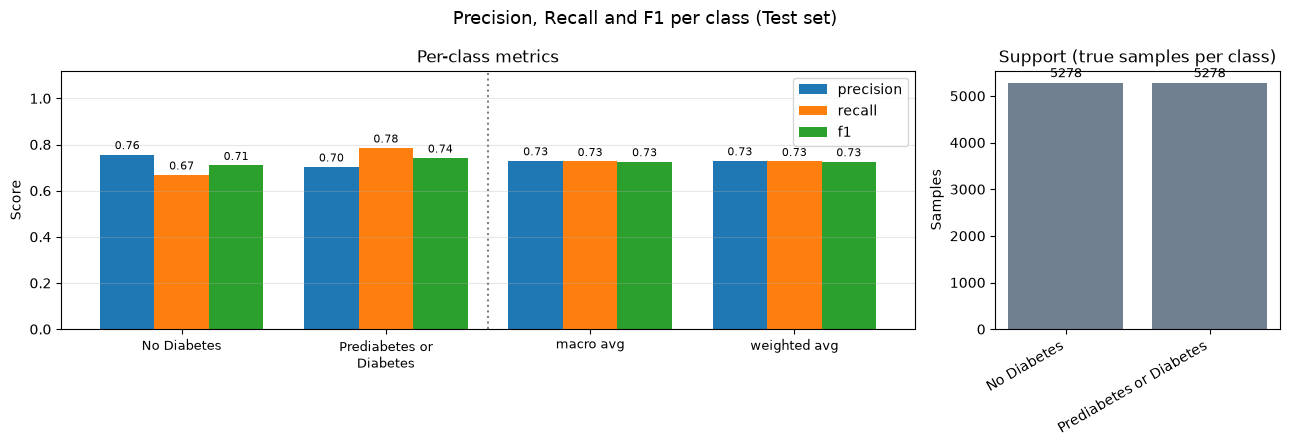

Check passed: weighted recall = accuracy = 0.7265


In [63]:
plot_classification_report(report_df, avg_df)

# Cross-check: the support-weighted recall must be equal to the accuracy
weighted_recall = (report_df["recall"] * report_df["support"]).sum() / report_df["support"].sum()
assert np.isclose(weighted_recall, test_acc), "Weighted recall should equal the accuracy — check your TP / FN counts"
print(f"Check passed: weighted recall = accuracy = {test_acc:.4f}")

### Questions (Precision, Recall, F1)
1. Compare the **accuracy** with the **macro F1**. Which one is lower? What does the difference tell you about the classes?
2. Which class has the **lowest recall**? Which one has the **lowest precision**? In plain words, what kind of mistake does the tree make for each of them (misses or false alarms)?
3. Use the confusion matrix to explain **one** of these numbers: point at the cells that form its TP, FP and FN.
4. Give an example (in this survey, or any other problem) where **recall** matters more than precision, and one where **precision** matters more.
5. Why does F1 use the *harmonic* mean instead of the ordinary average? Use your own numbers (or precision = 1.0, recall = 0.01) as an example.
6. When would **macro** and **weighted** averages differ a lot? Which one would you report for an imbalanced dataset, and why?
7. What does it mean if a class has precision = 0 and recall = 0? Does the accuracy show this problem?


**✏️ Your answer:** *(double-click to edit)*

if General Health <= 2.500:
|   if High Blood Pressure <= 0.500:
|   |   if Age <= 45.500:
|   |   |   --> class = No Diabetes(samples = 2733 , counts = None) [subtree hidden]
|   |   else:   # Age > 45.500
|   |   |   --> class = Prediabetes or Diabetes(samples = 8683 , counts = None) [subtree hidden]
|   else:   # High Blood Pressure > 0.500
|   |   if BMI <= 27.500:
|   |   |   --> class = Prediabetes or Diabetes(samples = 7076 , counts = None) [subtree hidden]
|   |   else:   # BMI > 27.500
|   |   |   --> class = Prediabetes or Diabetes(samples = 17578 , counts = None) [subtree hidden]
else:   # General Health > 2.500
|   if High Blood Pressure <= 0.500:
|   |   if Age <= 64.500:
|   |   |   --> class = No Diabetes(samples = 10856 , counts = None) [subtree hidden]
|   |   else:   # Age > 64.500
|   |   |   --> class = No Diabetes(samples = 3640 , counts = None) [subtree hidden]
|   else:   # High Blood Pressure > 0.500
|   |   if BMI <= 27.500:
|   |   |   --> class = No Diabetes(

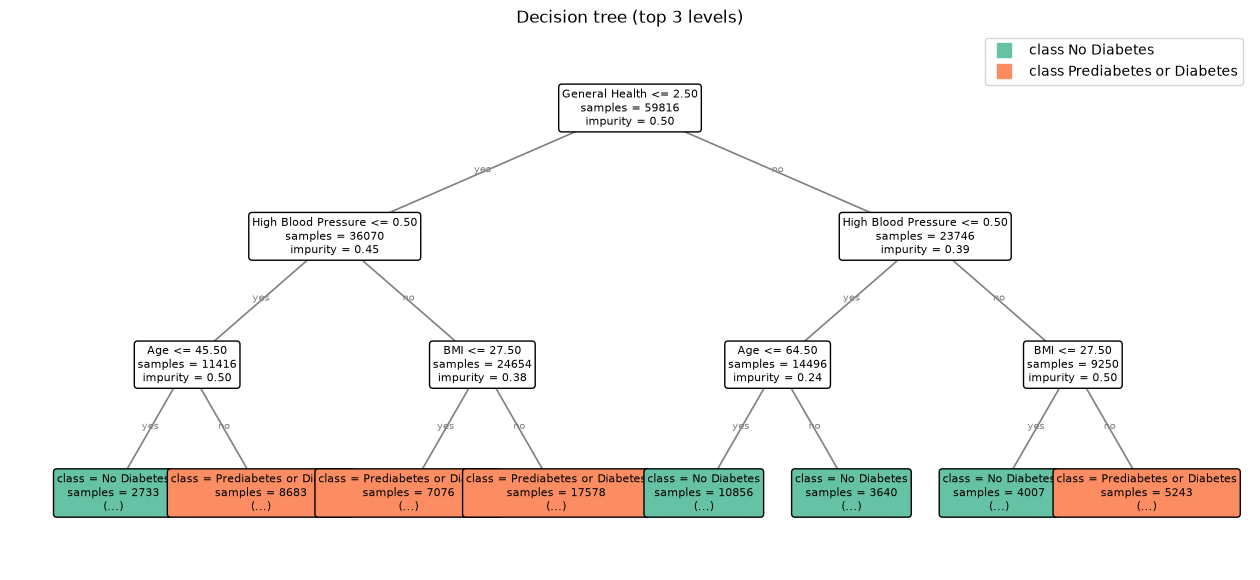

In [64]:
print_tree(final_tree, max_depth=3)      # top of the tree as rules
plot_tree(final_tree, max_depth=3)       # top of the tree as a picture

### Questions (Part L)
1. Is the Test accuracy close to the CV estimate? What does it mean if it is far away?
2. Why would it be wrong to choose the configuration by looking at Test accuracy?
3. Look at the confusion matrix: which class does the tree confuse most?


**✏️ Your answer:** *(double-click to edit)*

# Final Reflection

Answer briefly, in your own words, based on **your** results:

1. Explain overfitting and underfitting using your experiments.
2. Pre-Pruning vs Post-Pruning: what is the difference, and what did you observe?
3. Do Gini and Information Gain always give the same tree?
4. Why do we need a Validation set *and* a Test set?
5. Why is K-Fold CV better than a single Validation split? What is its cost?
6. What accuracy–complexity trade-off did you observe? Which model would you deploy, and why?


**✏️ Your answer:** *(double-click to edit)*

# Summary Table

Fill in with your actual results (Test accuracy **only** for the Final row) — or run the next cell to build the table automatically from the variables of the previous parts.

| Model | Criterion | Pruning | Train Acc. | Val Acc. (or CV mean) | Depth | Nodes | Leaves | Test Acc. |
|---|---|---|---:|---:|---:|---:|---:|---:|
| Baseline (majority) | – | – | | | – | – | – | – |
| Unrestricted | Information Gain | None | 0.9988 | 0.6563 | 38.0 | 25503 | 12752 | – |
| Pre-Pruned | Information Gain | Pre | 0.7596 | 0.7344 | 19.0 | 1441 | 721 | – |
| Post-Pruned | Information Gain | Post | 0.8727 | 0.7501 | 35.0 | 10281 | 5141 | – |
| Gini (depth 4) | Gini | Depth | 0.7315 | 0.7311 | 4 | 31 | 16 | – |
| **Final (Grid Search + CV)** | gini | Grid + CV | 0.7315 | 0.7283 | 4 | 31 | 16 | 0.7265 |

,Model,Criterion,Pruning,Train Acc.,Val Acc. (or CV mean),Depth,Nodes,Leaves,Test Acc.
0,Baseline (majority),–,–,NaN,0.5000,NaN,NaN,NaN,NaN
1,Unrestricted,entropy,None,0.9988,0.6563,38.0,25503.0,12752.0,NaN
2,Pre-Pruned,entropy,Pre,0.7596,0.7344,19.0,1441.0,721.0,NaN
3,Post-Pruned,entropy,Post,0.8727,0.7501,35.0,10281.0,5141.0,NaN
4,Gini (depth 4),gini,Depth,0.7315,0.7311,4.0,31.0,16.0,NaN
5,Final (Grid Search + CV),gini,Grid + CV,0.7315,0.7283,4.0,31.0,16.0,0.7265


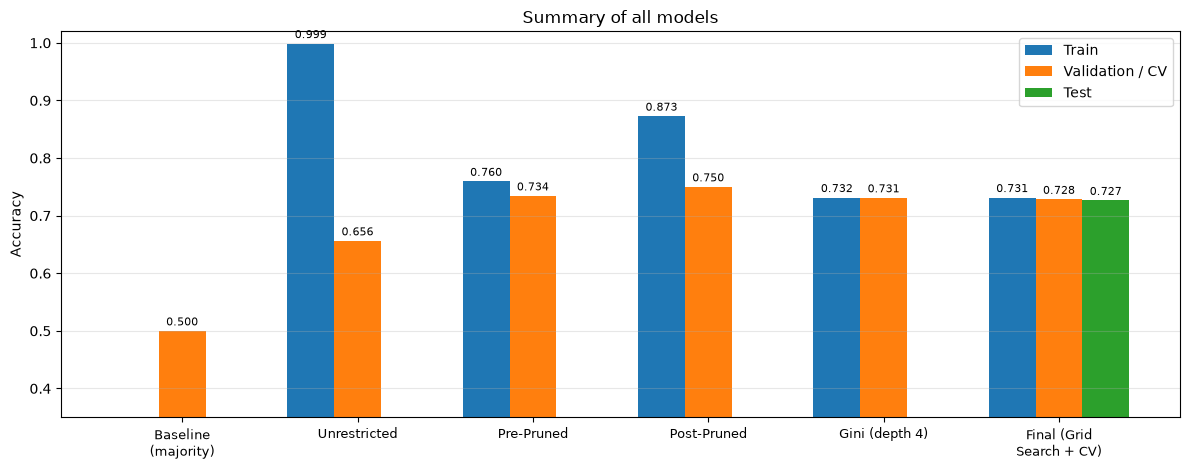

In [65]:
def _row(name, criterion, pruning, res, val_acc=None, test_acc=np.nan):
    return {"Model": name, "Criterion": criterion, "Pruning": pruning,
            "Train Acc.": res.get("train_acc", np.nan),
            "Val Acc. (or CV mean)": res["val_acc"] if val_acc is None else val_acc,
            "Depth": res.get("depth", np.nan), "Nodes": res.get("nodes", np.nan),
            "Leaves": res.get("leaves", np.nan), "Test Acc.": test_acc}

final_info = {"train_acc": accuracy_score_manual(y_dev, final_tree.predict(X_dev)), **complexity(final_tree)}

summary_df = pd.DataFrame([
    _row("Baseline (majority)", "–", "–", {"val_acc": baseline_val_acc}),
    _row("Unrestricted",  CRITERION,                "None", unrestricted),
    _row("Pre-Pruned",    pre_pruned["criterion"],  "Pre",  pre_pruned),
    _row("Post-Pruned",   CRITERION,                "Post", post_pruned),
    _row("Gini (depth 4)", "gini",                  "Depth", gini_res),
    _row("Final (Grid Search + CV)", FINAL_CRITERION, "Grid + CV", final_info,
         val_acc=float(suggested["cv_val_acc"]), test_acc=test_acc),
])
display(summary_df.round(4))

plot_summary(summary_df)

# Submission Checklist

- [ ] `DT_Library.py` passes **all** unit tests of Section I.
- [ ] Every **TODO** of Section II is completed (Part A helpers, Part B cleaning / split / missing values, experiments, cross-validation, grid search, final model).
- [ ] No scikit-learn is used anywhere; your own `stratified_train_test_split` is used for the split.
- [ ] Preprocessing is explained; Train/Val/Test split done once; baseline reported.
- [ ] Experiments 1–7 (Parts C–I) are completed with answers written in your own words.
- [ ] Post-Pruning implemented and compared with Pre-Pruning.
- [ ] K-Fold CV and Grid Search completed (Parts J–K), heatmap plotted.
- [ ] Final configuration chosen **before** looking at the Test set.
- [ ] Test accuracy computed once, at the end; confusion matrix, precision, recall and F1 computed and interpreted.
- [ ] Final tree visualized; summary table filled in.